# Stage 1 - seeded A/B/C ablation (full run)

Run **Setup** first, then cells **A**, **B** and **C**.

Each run cell is one complete experiment: 3 seeds, up to 40 epochs each,
with early stopping deciding where to stop. Roughly 1.5-2 hours per cell.
Results append to `stage1_results_seeded.csv` on Drive, so the three cells
can be run in separate sessions if Colab disconnects.

The three run cells are byte-identical apart from two or three config
lines. That is what makes them comparable.


## Setup


In [1]:
# %% =========================================================================
# SETUP - run this cell first, once per Colab session.
#
# Paste your Drive folder below. All three run cells read DRIVE_PATH from here,
# so the path is edited in exactly one place.
# ===========================================================================
DRIVE_PATH = "/content/drive/MyDrive/ganesh climate data"

import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("not on Colab, skipping drive mount")

if importlib.util.find_spec("lightning") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "pytorch-forecasting>=1.3", "lightning>=2.2"],
        check=True,
    )
    print("installed pytorch-forecasting + lightning")

import torch

print(f"torch {torch.__version__}  cuda={torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
else:
    print("  WARNING: no GPU. Runtime > Change runtime type > GPU, or each cell "
          "will take many hours.")

# Checked here rather than 3 minutes into Section 3, where a typo in the path
# surfaces as a confusing parquet error.
EXPECTED = [
    "gulf_coast_historical.parquet",
    "svi_gulf_coast_counties (1).csv",
    "station_county_mapping (1).csv",
    "gulf_coast_stations_official.csv",
]
root = Path(DRIVE_PATH)
assert root.is_dir(), f"DRIVE_PATH is not a directory: {root}"

print(f"\nDRIVE_PATH = {root}")
missing = []
for f in EXPECTED:
    p = root / f
    if p.exists():
        print(f"  ok    {f}  ({p.stat().st_size / 1e6:.1f} MB)")
    else:
        print(f"  MISS  {f}")
        missing.append(f)
assert not missing, f"missing files in {root}: {missing}"

print("\nsetup OK. Run cells A, B and C below, in order.")


Mounted at /content/drive
installed pytorch-forecasting + lightning
torch 2.11.0+cu130  cuda=True
  GPU: NVIDIA A100-SXM4-80GB

DRIVE_PATH = /content/drive/MyDrive/ganesh climate data
  ok    gulf_coast_historical.parquet  (72.8 MB)
  ok    svi_gulf_coast_counties (1).csv  (0.1 MB)
  ok    station_county_mapping (1).csv  (0.0 MB)
  ok    gulf_coast_stations_official.csv  (0.0 MB)

setup OK. Run cells A, B and C below, in order.


## A - baseline: SVI statics + absolute time


loaded cache daily_features_120_2000.parquet
(1168320, 27)
[A_baseline] counties=120 from=2000 svi=True abs_time=True statics=9 seeds=[0, 1, 2]


INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0


train windows 646,440 | val 218,880 | test 324,480 | select 41,980 (20 counties)
  validation decoder years: 2015-2019, no training windows included


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to th

┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │     74 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │    368 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │  7.5 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │  8.5 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │  2.6 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │    544 │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │     32 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │  1.4 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │    808 │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │    576 │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │    576 │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    119 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

...

[seed 2] done in 60.4 min

next-3-day extreme rainfall, test 2020-2026
  n 291,480  positives 2,891  prevalence 0.0099

  scoring                            seed 0     seed 1     seed 2     mean     std      lift
  county x month climatology         0.0128     0.0128     0.0128     0.0128   0.0000   1.29x
  TFT  raw upper quantile            0.0176     0.0147     0.0175     0.0166   0.0016   1.67x
  TFT  quantile / county threshold   0.0209     0.0178     0.0197     0.0195   0.0016   1.96x
  TFT  exceedance probability        0.0215     0.0176     0.0211     0.0201   0.0022   2.02x

  across-seed spread of the headline score (s_prob): 0.0039
  Any ablation effect smaller than this is not measurable with 3 seeds.
interpreting seed 2 (median test AP)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to th

  interpreting over 1,096 windows (4 counties, 2020 only)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


  xgb seed 0: 73 trees, test AP 0.0281
  xgb seed 1: 97 trees, test AP 0.0280
  xgb seed 2: 78 trees, test AP 0.0284
  XGBoost across-seed: mean 0.0282  std 0.0002  spread 0.0004

head-to-head, identical rows / features / thresholds, seeds paired
  seed 0:  n 291,480  prevalence 0.0099  XGB 0.0283 (2.85x)  TFT 0.0216 (2.18x)  diff +0.0067 [+0.0040, +0.0097]  SIGNIFICANT
  seed 1:  n 291,480  prevalence 0.0099  XGB 0.0282 (2.84x)  TFT 0.0177 (1.78x)  diff +0.0105 [+0.0073, +0.0140]  SIGNIFICANT
  seed 2:  n 291,480  prevalence 0.0099  XGB 0.0285 (2.88x)  TFT 0.0214 (2.15x)  diff +0.0072 [+0.0045, +0.0104]  SIGNIFICANT

  verdict across seeds: STABLE — SIGNIFICANT
  mean XGB - TFT gap +0.0081 vs largest training spread 0.0039: gap exceeds training noise

saved to stage1_results_seeded.csv
   run_tag  seed  counties  start_year  svi_statics  abs_time  n_rows  prevalence  ap_climatology  ap_tft_raw  ap_tft_ratio  ap_tft_prob   ap_xgb  xgb_minus_tft    ci_lo    ci_hi significant pilot  epoc

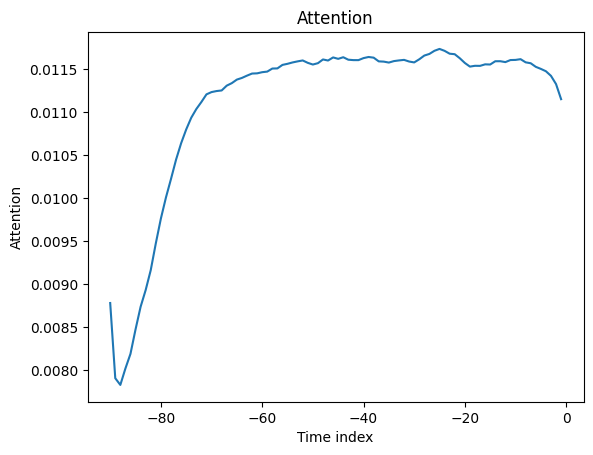

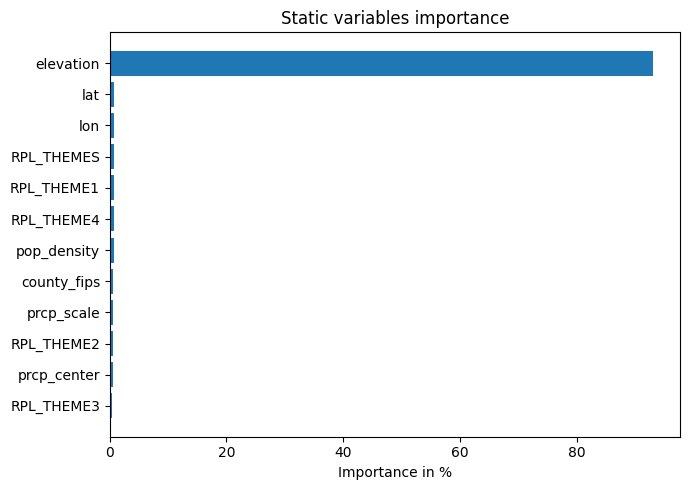

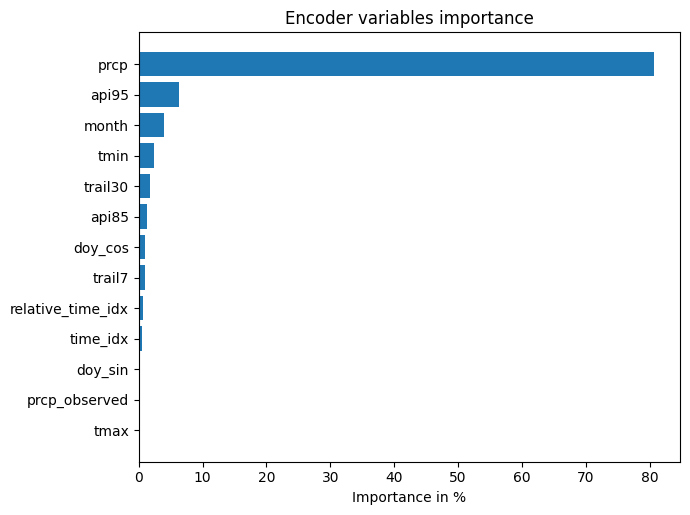

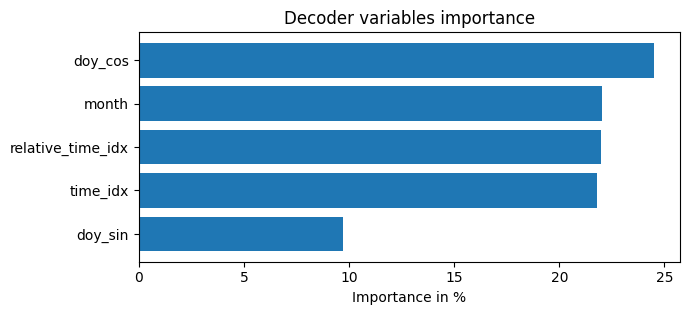

In [2]:
"""Temporal Fusion Transformer for Gulf Coast daily precipitation — Colab script.

Self-contained: reads the raw files from Drive, builds its own features, and
does not import anything from the local project.

The TFT predicts the daily precipitation *distribution* over the next 3 days via
quantile loss. Exceedance probability is then read off the predicted quantiles,
which is why this is the right job for a TFT rather than a classifier: XGBoost
gives one number per county-day, the TFT gives the whole predictive spread.

WHY THIS VERSION EXISTS
-----------------------
The previous script was run twice on the same three configs and disagreed with
itself: A scored 0.0150 then 0.0200, B scored 0.0234 then 0.0153. The spread
within one config was as large as the spread between configs, so the ablation
measured noise. Four changes fix that:

  1. Every run is seeded, and each config is trained at SEEDS = (0, 1, 2) so
     across-seed variance is measured instead of assumed away.
  2. The validation dataloader has a seeded generator, so the random subset
     `limit_val_batches` consumes is reproducible rather than fresh each run.
  3. The checkpoint is no longer selected on `val_loss`. Quantile loss on daily
     precipitation is dominated by the ~99% of ordinary days — it came out as
     2.0740 / 2.0799 / 2.0984 for three configs that differ by six input
     columns. Every epoch is now saved and the one with the best *validation
     exceedance AP* is chosen, which is the quantity the paper reports.
  4. The date-grouped bootstrap CI only ever measured test-set sampling
     variance. It is still reported, but now per seed, so a verdict that flips
     between seeds is visible instead of hidden.

A later audit found two more defects, fixed here:

  5. `validation` was built from the whole 2000-2019 frame with no
     `min_prediction_idx`, so all 646,440 training windows were validation
     windows too — 74.7% of `val_loss` was in-sample, and EarlyStopping was
     watching a loss that falls as the model memorises. Test and checkpoint
     selection were unaffected, so earlier test APs stand; the stopping rule
     did not.
  6. XGBoost was trained once on `random_state=0` and called deterministic.
     With subsample and colsample below 1 it is stochastic; a fixed seed
     freezes one draw. It is now seeded over the same three seeds and paired
     with the TFT, so the baseline's variance is measured rather than assumed.
"""

# %% =========================================================================
# SECTION 1 - install. Restart the runtime if Colab asks, then re-run 2 and 3.
# ===========================================================================
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("lightning") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "pytorch-forecasting>=1.3", "lightning>=2.2"],
        check=True,
    )

# %% =========================================================================
# SECTION 2 - config
# ===========================================================================
from pathlib import Path

# DRIVE_PATH is set once in the setup cell at the top of the notebook, so the
# path lives in exactly one place instead of being edited in all three cells.
# The fallback is for running this file directly as a .py.
try:
    DATA_DIR = Path(DRIVE_PATH)
except NameError:
    DATA_DIR = Path("/content/drive/MyDrive/ganesh climate data")

FILES = {
    "weather": "gulf_coast_historical.parquet",
    "svi": "svi_gulf_coast_counties (1).csv",
    "mapping": "station_county_mapping (1).csv",
    "stations": "gulf_coast_stations_official.csv",
}

START_YEAR = 2000          # widen to 1990 once the pipeline is proven
N_COUNTIES = 120           # None = all 356; start small, scale after it runs
MIN_COVERAGE = 0.95        # drop stations-counties with sparse precipitation

ENCODER_LEN = 90
# Every predicted day is scored, so none of the quantile-loss gradient is spent
# on horizons that get thrown away. The old PREDICT_LEN=7 wasted 4/7 of it.
PREDICT_LEN = 3

TRAIN_END = 2014
VAL_END = 2019
TEST_START_YEAR = 2019     # one warm-up year so 2020 windows have full encoders
EVAL_START_YEAR = 2020

# PILOT exists to prove the pipeline end to end on ~3 minutes of GPU per seed
# before committing five hours to it. Its average precisions are NOT results: two
# epochs is nowhere near convergence and EarlyStopping never gets to fire. It
# writes to its own CSV and its own checkpoint folder so pilot numbers can never
# be concatenated into the real table — merging two protocols into one table is
# the exact mistake that invalidated the previous pass.
PILOT = False

# An "epoch" is REAL_BATCHES*BATCH_SIZE windows, ~10% of the training index, so
# the ceiling is deliberately high and EarlyStopping decides where to stop.
REAL_EPOCHS = 2 if PILOT else 40
REAL_BATCHES = 500
# Raised from 100: val_loss on a 100-batch sample was noisy enough to move which
# epoch looked best. It now only gates when training stops, but a noisy stop
# signal still truncates the candidate list at a random point.
VAL_BATCHES = 200
# Raised from 5 because selection now happens after training. Stopping on
# val_loss too early would cut off epochs whose validation AP is still climbing.
PATIENCE = 8
BATCH_SIZE = 128
# 8, not 4. The bottleneck is Python assembling 90-day windows on the CPU, not
# the GPU — a 112K-param model running at 8 it/s is nowhere near an L4's limit.
# This speeds up both training and the per-epoch checkpoint scorings, which are
# together about half the runtime. Drop to 4 if a worker dies on RAM.
NUM_WORKERS = 8

# Three seeds per config. The whole point of this script: one number per config
# is not a result, it is a sample of size one.
SEEDS = (0, 1, 2)

# Checkpoint selection scores every saved epoch on held-out 2015-2019. Doing
# that on all 120 counties would cost more than the training run, so it uses
# every Nth county — a fixed subset is fine for *ranking* checkpoints against
# each other. Raise the stride if selection is slow, lower it if the chosen
# epoch looks unstable across seeds.
VAL_SCORE_STRIDE = 6

# --- ablation switches. Change one per run; the banner below labels the run. --
RUN_TAG = "A_baseline"
USE_SVI_STATICS = True
USE_ABS_TIME = True

# Colab's local disk is wiped on disconnect, so the selected checkpoints and the
# results table live on Drive. Per-epoch candidates stay on local disk — writing
# ~14 of them per seed across the Drive mount is slow and they are disposable.
CKPT_DIR = DATA_DIR / ("checkpoints_pilot" if PILOT else "checkpoints")
LOCAL_CKPT = Path("/content/ckpt_tmp")
RESULTS_CSV = DATA_DIR / (
    "stage1_results_PILOT.csv" if PILOT else "stage1_results_seeded.csv"
)
RETRAIN = True

# try:
#     from google.colab import drive
#     drive.mount("/content/drive")
# except ImportError:
#     pass

# %% =========================================================================
# SECTION 3 - build the daily long frame
# ===========================================================================
import numpy as np
import pandas as pd


def fips(s):
    return s.astype("int64").astype(str).str.zfill(5)


def load_daily():
    mapping = pd.read_csv(DATA_DIR / FILES["mapping"])
    mapping["county_fips"] = fips(mapping["county_fips"])

    w = pd.read_parquet(
        DATA_DIR / FILES["weather"], columns=["STATION", "DATE", "PRCP", "TMAX", "TMIN"]
    )
    w = w[w["DATE"].dt.year >= START_YEAR]
    w = w.merge(mapping[["STATION", "county_fips"]], on="STATION", how="inner")

    daily = (
        w.groupby(["county_fips", "DATE"])
        .agg(prcp=("PRCP", "mean"), tmax=("TMAX", "mean"), tmin=("TMIN", "mean"))
        .reset_index()
    )

    # Complete the calendar so the TFT sees a regular daily series per county.
    grid = pd.MultiIndex.from_product(
        [
            sorted(daily["county_fips"].unique()),
            pd.date_range(daily["DATE"].min(), daily["DATE"].max(), freq="D"),
        ],
        names=["county_fips", "DATE"],
    )
    daily = daily.set_index(["county_fips", "DATE"]).reindex(grid).reset_index()

    cov = daily.groupby("county_fips")["prcp"].apply(lambda s: s.notna().mean())
    keep = cov[cov >= MIN_COVERAGE].index
    if N_COUNTIES:
        keep = cov.loc[keep].sort_values(ascending=False).head(N_COUNTIES).index
    daily = daily[daily["county_fips"].isin(keep)].copy()
    print(f"kept {daily.county_fips.nunique()} counties, {len(daily):,} county-days")
    return daily


def load_static():
    svi = pd.read_csv(DATA_DIR / FILES["svi"])
    svi["county_fips"] = fips(svi["FIPS"])
    svi = svi[
        ["county_fips", "RPL_THEME1", "RPL_THEME2", "RPL_THEME3", "RPL_THEME4",
         "RPL_THEMES", "E_TOTPOP", "AREA_SQMI"]
    ]
    svi["pop_density"] = svi["E_TOTPOP"] / svi["AREA_SQMI"].replace(0, np.nan)

    mapping = pd.read_csv(DATA_DIR / FILES["mapping"])
    mapping["county_fips"] = fips(mapping["county_fips"])
    geo = mapping.groupby("county_fips").agg(
        lat=("LATITUDE", "mean"), lon=("LONGITUDE", "mean")
    ).reset_index()

    st = pd.read_csv(DATA_DIR / FILES["stations"]).merge(
        mapping[["STATION", "county_fips"]], left_on="ID", right_on="STATION"
    )
    elev = st.groupby("county_fips")["ELEVATION"].mean().rename("elevation").reset_index()

    return geo.merge(elev, on="county_fips", how="left").merge(
        svi, on="county_fips", how="inner"
    )


def add_features(daily):
    daily = daily.sort_values(["county_fips", "DATE"]).reset_index(drop=True)

    # A zero and a missing observation mean different things; flag it rather
    # than letting the model treat an outage as a dry day.
    daily["prcp_observed"] = daily["prcp"].notna().astype("float32")
    daily["prcp"] = daily["prcp"].fillna(0.0)
    for c in ("tmax", "tmin"):
        daily[c] = daily.groupby("county_fips")[c].ffill().bfill()

    g = daily.groupby("county_fips", sort=False)["prcp"]
    # Antecedent Precipitation Index: the soil-moisture memory term.
    for k in (0.85, 0.95):
        daily[f"api{int(k * 100)}"] = g.transform(
            lambda s, k=k: s.ewm(alpha=1 - k, adjust=False).mean()
        )
    for w in (7, 30):
        daily[f"trail{w}"] = g.transform(
            lambda s, w=w: s.rolling(w, min_periods=2).sum()
        ).fillna(0.0)

    # Evaluation-only column: sum of prcp over [t, t+1, t+2], matching the three
    # decoder positions of a window whose first decoder index is t. NEVER goes
    # into the feature list — it contains the answer.
    daily["fwd3"] = g.transform(lambda s: s.rolling(3).sum().shift(-2))

    daily["time_idx"] = (
        daily["DATE"] - daily["DATE"].min()
    ).dt.days.astype("int64")
    daily["year"] = daily["DATE"].dt.year
    doy = daily["DATE"].dt.dayofyear
    daily["doy_sin"] = np.sin(2 * np.pi * doy / 365.25).astype("float32")
    daily["doy_cos"] = np.cos(2 * np.pi * doy / 365.25).astype("float32")
    daily["month"] = daily["DATE"].dt.month.astype(str)

    daily = daily.merge(load_static(), on="county_fips", how="inner")
    for c in daily.select_dtypes("float64").columns:
        daily[c] = daily[c].astype("float32")
    return daily


# Cached because Section 3 re-reads a 72 MB parquet over the Drive mount and
# redoes every groupby on each runtime restart. The key carries the only two
# settings that change the frame; delete the file if the feature code changes.
CACHE = DATA_DIR / f"daily_features_{N_COUNTIES or 'all'}_{START_YEAR}.parquet"
if CACHE.exists():
    daily = pd.read_parquet(CACHE)
    print(f"loaded cache {CACHE.name}")
else:
    daily = add_features(load_daily())
    daily.to_parquet(CACHE, index=False)
print(daily.shape)

# %% =========================================================================
# SECTION 4 - TimeSeriesDataSet
# ===========================================================================
import lightning.pytorch as pl
import torch
from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
from pytorch_forecasting import GroupNormalizer, TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_forecasting.metrics import QuantileLoss

torch.set_float32_matmul_precision("medium")

# SVI themes and population density are *vulnerability* variables with no
# mechanism for predicting rainfall; in a hazard model they can only act as a
# county fingerprint. Whether removing them actually helps is what the A/B
# comparison is for — the first attempt said +56% and the repeat said -35%.
STATIC_REALS = ["lat", "lon", "elevation"]
if USE_SVI_STATICS:
    STATIC_REALS += ["pop_density", "RPL_THEME1", "RPL_THEME2",
                     "RPL_THEME3", "RPL_THEME4", "RPL_THEMES"]

KNOWN_REALS = ["doy_sin", "doy_cos"] + (["time_idx"] if USE_ABS_TIME else [])

print(f"[{RUN_TAG}] counties={N_COUNTIES} from={START_YEAR} "
      f"svi={USE_SVI_STATICS} abs_time={USE_ABS_TIME} "
      f"statics={len(STATIC_REALS)} seeds={list(SEEDS)}")

train_cutoff = daily.loc[daily.year <= TRAIN_END, "time_idx"].max()
val_cutoff = daily.loc[daily.year <= VAL_END, "time_idx"].max()

# Frozen on the training years only. Defined here rather than in Section 7
# because checkpoint selection, test scoring and XGBoost all need it.
thr_by_county = (
    daily[daily.year <= TRAIN_END]
    .groupby("county_fips")["fwd3"].quantile(0.99).rename("thr")
)

# County x month climatology, also train-period only. Tier-0 comparator.
daily["_y3"] = (daily["fwd3"] >= daily["county_fips"].map(thr_by_county)).astype(float)
clim = (
    daily[daily.year <= TRAIN_END]
    .groupby(["county_fips", "month"])["_y3"].mean().rename("s_clim")
)


def make_dataset(df, max_idx, **kw):
    return TimeSeriesDataSet(
        df[df.time_idx <= max_idx],
        time_idx="time_idx",
        target="prcp",
        group_ids=["county_fips"],
        max_encoder_length=ENCODER_LEN,
        min_encoder_length=ENCODER_LEN,
        max_prediction_length=PREDICT_LEN,
        min_prediction_length=PREDICT_LEN,
        static_categoricals=["county_fips"],
        static_reals=STATIC_REALS,
        time_varying_known_categoricals=["month"],
        time_varying_known_reals=KNOWN_REALS,
        time_varying_unknown_reals=[
            "prcp", "tmax", "tmin", "api85", "api95", "trail7", "trail30",
            "prcp_observed",
        ],
        # Daily rainfall is zero-inflated and right-skewed; log1p inside a
        # per-county normalizer keeps the quantile head on a sane scale.
        target_normalizer=GroupNormalizer(
            groups=["county_fips"], transformation="log1p"
        ),
        add_relative_time_idx=True,
        add_target_scales=True,
        allow_missing_timesteps=True,
        **kw,
    )


training = make_dataset(daily, train_cutoff)

# min_prediction_idx is load-bearing. Without it this builds a window at every
# valid position in 2000-2019, so all 646,440 training windows are validation
# windows too and 74.7% of val_loss is in-sample — which makes EarlyStopping
# watch a loss that falls as the model memorises. Encoders still reach back into
# 2014, which is correct: reading the past is not leakage.
validation = TimeSeriesDataSet.from_dataset(
    training,
    daily[daily.time_idx <= val_cutoff],
    min_prediction_idx=train_cutoff + 1,
    predict=False,
    stop_randomization=True,
)
# Only the evaluation years, plus one warm-up year for the encoders. Scoring all
# 26 years and then discarding pre-2020 was ~4x wasted inference.
testing = TimeSeriesDataSet.from_dataset(
    training,
    daily[daily.year >= TEST_START_YEAR],
    predict=False,
    stop_randomization=True,
)

# Held-out slice used only to pick which epoch's weights to keep. 2014 is a
# warm-up year so that 2015 windows have full encoders; nothing from it is
# scored, and no test year is touched.
val_score_counties = sorted(daily.county_fips.unique())[::VAL_SCORE_STRIDE]
val_scoring = TimeSeriesDataSet.from_dataset(
    training,
    daily[(daily.year >= TRAIN_END) & (daily.year <= VAL_END)
          & daily.county_fips.isin(val_score_counties)],
    predict=False,
    stop_randomization=True,
)

print(f"train windows {len(training):,} | val {len(validation):,} | "
      f"test {len(testing):,} | select {len(val_scoring):,} "
      f"({len(val_score_counties)} counties)")

# Fails loudly if min_prediction_idx ever goes missing again. Validation must be
# strictly smaller than training here, because it covers 5 years against 15.
assert len(validation) < len(training), (
    f"validation ({len(validation):,}) >= training ({len(training):,}): the "
    "validation set is overlapping the training years again"
)
print(f"  validation decoder years: "
      f"{daily.loc[daily.time_idx == train_cutoff + 1, 'year'].iloc[0]}"
      f"-{VAL_END}, no training windows included")

test_dl = testing.to_dataloader(
    train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS
)
val_score_dl = val_scoring.to_dataloader(
    train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS
)

# %% =========================================================================
# SECTION 5 - scoring, shared by checkpoint selection and final evaluation
#
# Three scorings of the same predictions. The first is the naive one and it is
# expected to fail: average precision ranks globally, but the label is a
# *per-county* p99, so a wet county's high predicted quantiles carry no label
# information and only add between-county noise. The second and third remove
# that county scale, which is the comparison XGBoost has always had.
# ===========================================================================
from sklearn.metrics import average_precision_score


def to_np(t):
    return t.detach().cpu().numpy() if hasattr(t, "detach") else np.asarray(t)


def exceedance_scores(model, dl):
    """Return one row per window with the label and all four ranking scores."""
    out = model.predict(dl, mode="quantiles", return_index=True, return_y=True)

    qsum = to_np(out.output).sum(axis=1)     # (n, n_quantiles), 3-day totals
    # TFT quantile heads cross occasionally. The insertion-point search below
    # assumes a monotone vector, and on a crossed row it returns a count rather
    # than a position, which silently corrupts that row's s_prob.
    qsum = np.maximum.accumulate(qsum, axis=1)
    actual3 = to_np(out.y[0]).sum(axis=1)

    ev = out.index.reset_index(drop=True).assign(actual3=actual3)
    ev = ev.merge(daily[["county_fips", "time_idx", "year", "month"]],
                  on=["county_fips", "time_idx"], how="left")
    ev = ev.join(thr_by_county, on="county_fips").dropna(subset=["thr"])
    ev["y"] = (ev["actual3"] >= ev["thr"]).astype(int)

    qsum = qsum[ev.index.to_numpy()]
    thr = ev["thr"].to_numpy()

    # scoring 1: raw upper quantile, county scale left in
    ev["s_raw"] = qsum[:, -1]
    # scoring 2: upper quantile divided by the county's own threshold
    ev["s_ratio"] = qsum[:, -1] / thr
    # scoring 3: P(3-day total > county threshold), interpolated across the
    # predicted quantile vector. The quantile of a sum is not the sum of
    # quantiles, so this is a ranking score, not a calibrated probability.
    L = np.asarray(model.loss.quantiles, dtype=float)
    k = (qsum < thr[:, None]).sum(axis=1)
    k_lo, k_hi = np.clip(k - 1, 0, len(L) - 1), np.clip(k, 0, len(L) - 1)
    v_lo = np.take_along_axis(qsum, k_lo[:, None], 1).ravel()
    v_hi = np.take_along_axis(qsum, k_hi[:, None], 1).ravel()
    span = np.where(v_hi > v_lo, v_hi - v_lo, 1.0)
    frac = np.clip((thr - v_lo) / span, 0.0, 1.0)
    cdf = L[k_lo] + frac * (L[k_hi] - L[k_lo])
    cdf = np.where(k == 0, 0.0, np.where(k == len(L), 1.0, cdf))
    ev["s_prob"] = 1.0 - cdf

    ev = ev.join(clim, on=["county_fips", "month"])
    ev["s_clim"] = ev["s_clim"].fillna(ev["s_clim"].mean())
    return ev.reset_index(drop=True)


SCORINGS = [
    ("county x month climatology", "s_clim"),
    ("TFT  raw upper quantile", "s_raw"),
    ("TFT  quantile / county threshold", "s_ratio"),
    ("TFT  exceedance probability", "s_prob"),
]

# %% =========================================================================
# SECTION 6 - SMOKE TEST: can the model overfit a tiny subset?
# If the loss does not collapse here, something is wrong with the windowing or
# the target. Catching it on 100 samples costs 30 seconds; catching it after a
# full run costs an evening.
# ===========================================================================
pl.seed_everything(SEEDS[0], workers=True)

tiny_counties = daily.county_fips.unique()[:2]
tiny = daily[
    (daily.county_fips.isin(tiny_counties)) & (daily.time_idx <= daily.time_idx.min() + 400)
]
tiny_ds = make_dataset(tiny, tiny.time_idx.max())
tiny_dl = tiny_ds.to_dataloader(train=True, batch_size=32, num_workers=0)

tiny_model = TemporalFusionTransformer.from_dataset(
    tiny_ds,
    learning_rate=0.05,
    hidden_size=16,
    attention_head_size=2,
    dropout=0.0,
    hidden_continuous_size=8,
    loss=QuantileLoss(),
    optimizer="adam",
)
pl.Trainer(
    max_epochs=40, accelerator="auto", devices=1, enable_progress_bar=True,
    logger=False, enable_checkpointing=False, gradient_clip_val=0.1,
).fit(tiny_model, train_dataloaders=tiny_dl)
print("\nSmoke test done. The training loss above must fall substantially.")
print("If it is flat, STOP and debug before running Section 7.")

# %% =========================================================================
# SECTION 7 - train one model per seed, select its epoch on validation AP
#
# `val_loss` is deliberately NOT the selection criterion. It is quantile loss
# over daily precipitation, so the ~99% of ordinary days drown out the extremes
# the paper is about: three configs differing by six input columns scored
# 2.0740 / 2.0799 / 2.0984. It is kept only to decide when to stop training.
# ===========================================================================
import shutil
import time

per_seed = {}
LOCAL_CKPT.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

for SEED in SEEDS:
    t0 = time.time()
    final_ckpt = CKPT_DIR / f"{RUN_TAG}-seed{SEED}.ckpt"

    if not RETRAIN and final_ckpt.exists():
        best = TemporalFusionTransformer.load_from_checkpoint(str(final_ckpt))
        print(f"\n[seed {SEED}] loaded {final_ckpt.name} — skipped training")
    else:
        pl.seed_everything(SEED, workers=True)

        tmp = LOCAL_CKPT / f"{RUN_TAG}_seed{SEED}"
        if tmp.exists():
            shutil.rmtree(tmp)
        tmp.mkdir(parents=True)

        # Explicit generator, not the global RNG. Without it the batch order
        # depends on how many draws model construction happened to consume,
        # which differs between A/B/C because they have different parameter
        # counts — so "seed 0" would not mean the same shuffle across configs.
        train_dl = training.to_dataloader(
            train=True, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
            persistent_workers=True,
            generator=torch.Generator().manual_seed(SEED),
        )
        # shuffle=True matters because limit_val_batches takes the *first* n
        # batches and the dataset index is ordered by county. The seeded
        # generator is what makes the subset reproducible between runs — without
        # it, every run validated on a different sample and the epoch that
        # looked best was partly a coin flip.
        val_dl = validation.to_dataloader(
            train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS,
            persistent_workers=True, shuffle=True,
            generator=torch.Generator().manual_seed(SEED),
        )

        model = TemporalFusionTransformer.from_dataset(
            training,
            learning_rate=0.01,
            hidden_size=32,
            attention_head_size=4,
            dropout=0.15,
            hidden_continuous_size=16,
            loss=QuantileLoss(),
            optimizer="adam",
            log_interval=50,
            reduce_on_plateau_patience=2,
        )
        if SEED == SEEDS[0]:
            print(f"{model.size() / 1e3:.1f}k parameters")

        # save_top_k=-1: keep every epoch, because the epoch that minimises
        # val_loss is not the epoch that maximises validation AP.
        ckpt = ModelCheckpoint(
            dirpath=str(tmp), filename="{epoch:02d}",
            save_top_k=-1, every_n_epochs=1,
        )
        trainer = pl.Trainer(
            max_epochs=REAL_EPOCHS,
            limit_train_batches=REAL_BATCHES,
            limit_val_batches=VAL_BATCHES,
            accelerator="auto",
            devices=1,
            gradient_clip_val=0.1,
            deterministic="warn",
            callbacks=[
                EarlyStopping(monitor="val_loss", patience=PATIENCE, mode="min"),
                LearningRateMonitor(),
                ckpt,
            ],
        )
        trainer.fit(model, train_dataloaders=train_dl, val_dataloaders=val_dl)
        del train_dl, val_dl

        cands = sorted(tmp.glob("*.ckpt"))
        print(f"\n[seed {SEED}] trained {trainer.current_epoch} epochs, "
              f"scoring {len(cands)} checkpoints on held-out {TRAIN_END + 1}-{VAL_END}")

        sel_ap, sel_path = -1.0, None
        for p in cands:
            m = TemporalFusionTransformer.load_from_checkpoint(str(p))
            vs = exceedance_scores(m, val_score_dl)
            vs = vs[vs.year > TRAIN_END]
            ap = average_precision_score(vs["y"], vs["s_prob"])
            flag = ""
            if ap > sel_ap:
                sel_ap, sel_path, flag = ap, p, "  <-- best so far"
            print(f"    {p.stem}  val AP {ap:.4f}{flag}")
            del m
            torch.cuda.empty_cache()

        shutil.copy(sel_path, final_ckpt)
        shutil.rmtree(tmp)
        best = TemporalFusionTransformer.load_from_checkpoint(str(final_ckpt))
        print(f"[seed {SEED}] selected {sel_path.stem} "
              f"(val AP {sel_ap:.4f}) -> {final_ckpt.name}")

    ev = exceedance_scores(best, test_dl)
    per_seed[SEED] = ev[ev.year >= EVAL_START_YEAR].reset_index(drop=True)
    print(f"[seed {SEED}] done in {(time.time() - t0) / 60:.1f} min")

# --- per-seed and across-seed test results ----------------------------------
prev = per_seed[SEEDS[0]]["y"].mean()
print(f"\nnext-3-day extreme rainfall, test {EVAL_START_YEAR}-2026")
print(f"  n {len(per_seed[SEEDS[0]]):,}  "
      f"positives {per_seed[SEEDS[0]].y.sum():,}  prevalence {prev:.4f}\n")

ap_table = pd.DataFrame(
    {col: {s: average_precision_score(te["y"], te[col])
           for s, te in per_seed.items()}
     for _, col in SCORINGS}
)
ap_table.index.name = "seed"

print(f"  {'scoring':<34} " + "".join(f"seed {s:<6}" for s in SEEDS)
      + f"{'mean':<9}{'std':<9}lift")
for name, col in SCORINGS:
    v = ap_table[col].to_numpy()
    print(f"  {name:<34} " + "".join(f"{x:<11.4f}" for x in v)
          + f"{v.mean():<9.4f}{v.std(ddof=1):<9.4f}{v.mean() / prev:.2f}x")

spread = ap_table["s_prob"].max() - ap_table["s_prob"].min()
print(f"\n  across-seed spread of the headline score (s_prob): {spread:.4f}")
print("  Any ablation effect smaller than this is not measurable with 3 seeds.")

# %% =========================================================================
# SECTION 8 - interpretability, on the median seed
# ===========================================================================
median_seed = ap_table["s_prob"].sort_values().index[len(SEEDS) // 2]
print(f"interpreting seed {median_seed} (median test AP)")
best = TemporalFusionTransformer.load_from_checkpoint(
    str(CKPT_DIR / f"{RUN_TAG}-seed{median_seed}.ckpt")
)
# mode="raw" keeps the attention tensor for every window, so running it over all
# 324,480 test windows is an out-of-memory crash, not a slow cell. Attention is
# averaged with reduction="sum" anyway, so a few thousand windows give the same
# picture; the interp dataloader is deliberately a thin slice.
interp = TimeSeriesDataSet.from_dataset(
    training,
    daily[(daily.year == EVAL_START_YEAR)
          & daily.county_fips.isin(val_score_counties[:4])],
    predict=False,
    stop_randomization=True,
)
print(f"  interpreting over {len(interp):,} windows (4 counties, "
      f"{EVAL_START_YEAR} only)")
raw = best.predict(
    interp.to_dataloader(train=False, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS),
    mode="raw", return_x=True,
)
best.plot_interpretation(best.interpret_output(raw.output, reduction="sum"))

# %% =========================================================================
# SECTION 9 - head-to-head: XGBoost on IDENTICAL rows and IDENTICAL features
#
# XGBoost is seeded over the SAME three seeds as the TFT. The earlier script
# trained it once and argued `random_state=0` made it deterministic — but with
# subsample=0.8 and colsample_bytree=0.7 the method is stochastic, and fixing
# the seed freezes one draw rather than removing the variance. Measuring the
# TFT's training variance and then comparing it against a single unmeasured
# baseline draw is the same error that invalidated the first ablation.
#
# Seeds are paired: TFT seed s against XGBoost seed s. The bootstrap CI is also
# per pair, which is the point — in the earlier script one seed printed
# SIGNIFICANT with a tight interval while a repeat of the same config disagreed
# by more than that interval's width.
# ===========================================================================
import xgboost as xgb

FEAT = ["prcp", "tmax", "tmin", "prcp_observed", "api85", "api95",
        "trail7", "trail30", "doy_sin", "doy_cos", "lat", "lon", "elevation"]

# Features are read at t-1, matching the TFT encoder, which ends the day before
# the first decoder step. Shifting time_idx forward relabels row t-1 as t.
origin = daily[["county_fips", "time_idx"] + FEAT].copy()
origin["time_idx"] += 1

lab = daily[["county_fips", "time_idx", "year", "fwd3"]].copy()
lab = lab.join(thr_by_county, on="county_fips").dropna(subset=["thr", "fwd3"])
lab["y"] = (lab["fwd3"] >= lab["thr"]).astype(int)

xd = lab.merge(origin, on=["county_fips", "time_idx"], how="inner").dropna(subset=FEAT)
tr = xd[xd.year <= TRAIN_END]
va = xd[(xd.year > TRAIN_END) & (xd.year <= VAL_END)]
xte = xd.merge(per_seed[SEEDS[0]][["county_fips", "time_idx"]].drop_duplicates(),
               on=["county_fips", "time_idx"], how="inner")

spw = (len(tr) - tr.y.sum()) / max(tr.y.sum(), 1)

xgb_pred, xgb_ap = {}, {}
for XSEED in SEEDS:
    clf = xgb.XGBClassifier(
        n_estimators=1500, learning_rate=0.05, max_depth=6, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.7, reg_lambda=2.0, scale_pos_weight=spw,
        eval_metric="aucpr", early_stopping_rounds=60, tree_method="hist",
        n_jobs=-1, random_state=XSEED,
    )
    clf.fit(tr[FEAT], tr.y, eval_set=[(va[FEAT], va.y)], verbose=False)
    xgb_pred[XSEED] = xte[["county_fips", "time_idx", "y"]].assign(
        p_xgb=clf.predict_proba(xte[FEAT])[:, 1]
    )
    xgb_ap[XSEED] = average_precision_score(xte["y"], xgb_pred[XSEED]["p_xgb"])
    print(f"  xgb seed {XSEED}: {clf.best_iteration + 1} trees, "
          f"test AP {xgb_ap[XSEED]:.4f}")

xv = np.array([xgb_ap[s] for s in SEEDS])
print(f"  XGBoost across-seed: mean {xv.mean():.4f}  std {xv.std(ddof=1):.4f}  "
      f"spread {xv.max() - xv.min():.4f}")

print("\nhead-to-head, identical rows / features / thresholds, seeds paired")
h2h = {}
for SEED, te in per_seed.items():
    cmp = xgb_pred[SEED].merge(te[["county_fips", "time_idx", "s_prob"]],
                               on=["county_fips", "time_idx"], how="inner").reset_index(drop=True)
    prev_c = cmp["y"].mean()

    # Resample whole days, not rows: one storm covers many counties on one date,
    # so row-level resampling would badly understate the interval. Note this
    # captures test-set sampling variance only — the across-seed spread above is
    # the other half of the uncertainty and the two must be read together.
    rng = np.random.default_rng(0)
    by_day = cmp.groupby("time_idx").indices
    days = np.array(list(by_day))
    a_x, a_t, diff = [], [], []
    for _ in range(200):
        sel = np.concatenate([by_day[d] for d in rng.choice(days, len(days), replace=True)])
        s = cmp.iloc[sel]
        if s["y"].sum() == 0:
            continue
        ax = average_precision_score(s["y"], s["p_xgb"])
        at = average_precision_score(s["y"], s["s_prob"])
        a_x.append(ax)
        a_t.append(at)
        diff.append(ax - at)

    lo, hi = np.percentile(diff, [2.5, 97.5])
    verdict = "SIGNIFICANT" if lo > 0 or hi < 0 else "NOT significant"
    h2h[SEED] = dict(n=len(cmp), prevalence=prev_c, ap_xgb=float(np.mean(a_x)),
                     ap_tft=float(np.mean(a_t)), diff=float(np.mean(diff)),
                     ci_lo=lo, ci_hi=hi, significant=verdict)
    print(f"  seed {SEED}:  n {len(cmp):,}  prevalence {prev_c:.4f}  "
          f"XGB {np.mean(a_x):.4f} ({np.mean(a_x) / prev_c:.2f}x)  "
          f"TFT {np.mean(a_t):.4f} ({np.mean(a_t) / prev_c:.2f}x)  "
          f"diff {np.mean(diff):+.4f} [{lo:+.4f}, {hi:+.4f}]  {verdict}")

verdicts = {v["significant"] for v in h2h.values()}
print(f"\n  verdict across seeds: "
      + ("STABLE — " + verdicts.pop() if len(verdicts) == 1
         else "UNSTABLE, the comparison flips between seeds: " + ", ".join(sorted(verdicts))))

# The gap only means something if it is larger than the variance of BOTH models.
gap = float(np.mean([v["diff"] for v in h2h.values()]))
noise = max(spread, xv.max() - xv.min())
print(f"  mean XGB - TFT gap {gap:+.4f} vs largest training spread {noise:.4f}: "
      + ("gap exceeds training noise" if abs(gap) > noise
         else "gap is WITHIN training noise, not a finding"))

if PILOT:
    print("\n" + "=" * 70)
    print("PILOT RUN — 2 epochs per seed. Every AP above is pre-convergence and")
    print("must not be quoted, compared across configs, or put in the paper.")
    print("What it does prove: the data, windowing, seeding, selection, scoring")
    print("and XGBoost paths all execute. Set PILOT = False for real numbers.")
    print("=" * 70)

# %% =========================================================================
# SECTION 10 - append one row per seed to the results table on Drive
# ===========================================================================
rows = pd.DataFrame([{
    "run_tag": RUN_TAG,
    "seed": SEED,
    "pilot": PILOT,
    "epochs_cap": REAL_EPOCHS,
    "counties": daily.county_fips.nunique(),
    "start_year": START_YEAR,
    "svi_statics": USE_SVI_STATICS,
    "abs_time": USE_ABS_TIME,
    "n_rows": h2h[SEED]["n"],
    "prevalence": h2h[SEED]["prevalence"],
    "ap_climatology": ap_table.loc[SEED, "s_clim"],
    "ap_tft_raw": ap_table.loc[SEED, "s_raw"],
    "ap_tft_ratio": ap_table.loc[SEED, "s_ratio"],
    "ap_tft_prob": ap_table.loc[SEED, "s_prob"],
    "ap_xgb": h2h[SEED]["ap_xgb"],
    "xgb_minus_tft": h2h[SEED]["diff"],
    "ci_lo": h2h[SEED]["ci_lo"],
    "ci_hi": h2h[SEED]["ci_hi"],
    "significant": h2h[SEED]["significant"],
} for SEED in SEEDS])

if RESULTS_CSV.exists():
    rows = pd.concat([pd.read_csv(RESULTS_CSV), rows], ignore_index=True)
    rows = rows.drop_duplicates(subset=["run_tag", "seed"], keep="last")
rows = rows.sort_values(["run_tag", "seed"])
rows.to_csv(RESULTS_CSV, index=False)
print(f"\nsaved to {RESULTS_CSV.name}")
print(rows.to_string(index=False))

print("\nper-config summary across seeds")
print(rows.groupby("run_tag")["ap_tft_prob"].agg(["mean", "std", "min", "max"]).to_string())


## B - no SVI statics


loaded cache daily_features_120_2000.parquet
(1168320, 27)
[B_no_svi] counties=120 from=2000 svi=False abs_time=True statics=3 seeds=[0, 1, 2]


INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0


train windows 646,440 | val 218,880 | test 324,480 | select 41,980 (20 counties)
  validation decoder years: 2015-2019, no training windows included


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to th

┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │     74 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │    272 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │  3.1 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │  8.5 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │  2.6 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │    544 │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │     32 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │  1.4 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │    808 │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │    576 │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │    576 │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    119 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

...

[seed 2] done in 57.1 min

next-3-day extreme rainfall, test 2020-2026
  n 291,480  positives 2,891  prevalence 0.0099

  scoring                            seed 0     seed 1     seed 2     mean     std      lift
  county x month climatology         0.0128     0.0128     0.0128     0.0128   0.0000   1.29x
  TFT  raw upper quantile            0.0169     0.0156     0.0158     0.0161   0.0007   1.63x
  TFT  quantile / county threshold   0.0202     0.0192     0.0186     0.0193   0.0008   1.95x
  TFT  exceedance probability        0.0206     0.0184     0.0207     0.0199   0.0013   2.00x

  across-seed spread of the headline score (s_prob): 0.0023
  Any ablation effect smaller than this is not measurable with 3 seeds.
interpreting seed 0 (median test AP)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to th

  interpreting over 1,096 windows (4 counties, 2020 only)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


  xgb seed 0: 73 trees, test AP 0.0281
  xgb seed 1: 97 trees, test AP 0.0280
  xgb seed 2: 78 trees, test AP 0.0284
  XGBoost across-seed: mean 0.0282  std 0.0002  spread 0.0004

head-to-head, identical rows / features / thresholds, seeds paired
  seed 0:  n 291,480  prevalence 0.0099  XGB 0.0283 (2.85x)  TFT 0.0207 (2.09x)  diff +0.0076 [+0.0048, +0.0109]  SIGNIFICANT
  seed 1:  n 291,480  prevalence 0.0099  XGB 0.0282 (2.84x)  TFT 0.0184 (1.86x)  diff +0.0097 [+0.0064, +0.0135]  SIGNIFICANT
  seed 2:  n 291,480  prevalence 0.0099  XGB 0.0285 (2.88x)  TFT 0.0209 (2.11x)  diff +0.0076 [+0.0050, +0.0107]  SIGNIFICANT

  verdict across seeds: STABLE — SIGNIFICANT
  mean XGB - TFT gap +0.0083 vs largest training spread 0.0023: gap exceeds training noise

saved to stage1_results_seeded.csv
   run_tag  seed  counties  start_year  svi_statics  abs_time  n_rows  prevalence  ap_climatology  ap_tft_raw  ap_tft_ratio  ap_tft_prob   ap_xgb  xgb_minus_tft    ci_lo    ci_hi significant  pilot  epo

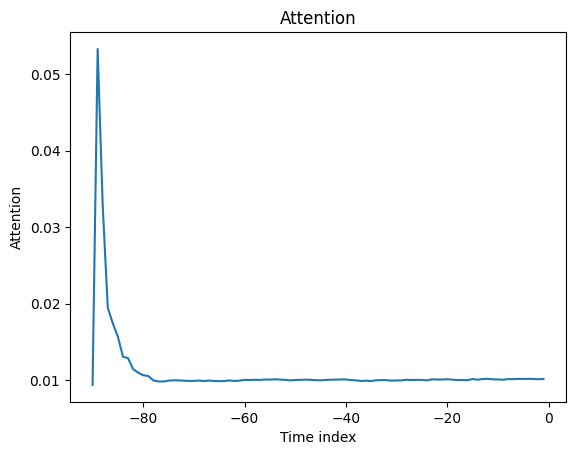

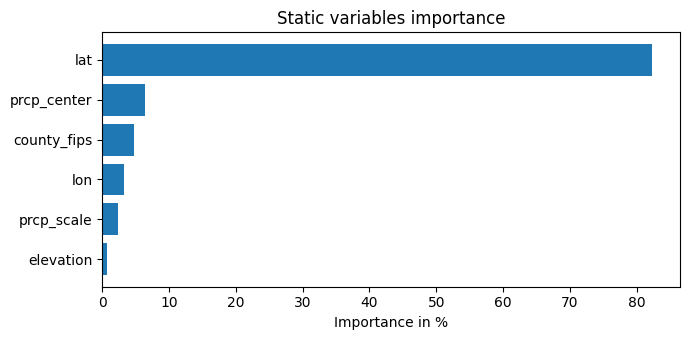

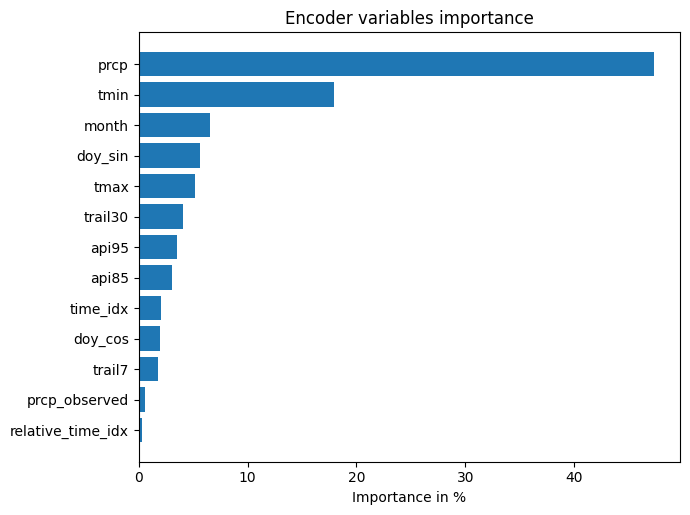

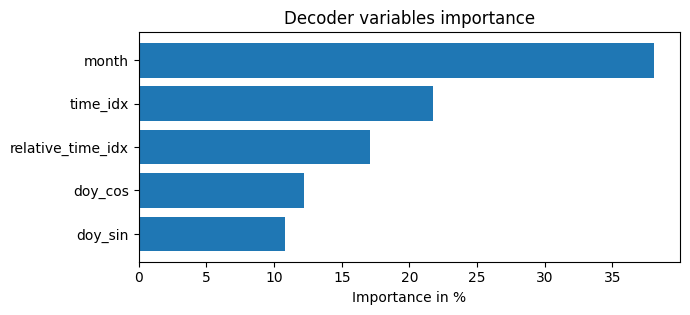

In [3]:
"""Temporal Fusion Transformer for Gulf Coast daily precipitation — Colab script.

Self-contained: reads the raw files from Drive, builds its own features, and
does not import anything from the local project.

The TFT predicts the daily precipitation *distribution* over the next 3 days via
quantile loss. Exceedance probability is then read off the predicted quantiles,
which is why this is the right job for a TFT rather than a classifier: XGBoost
gives one number per county-day, the TFT gives the whole predictive spread.

WHY THIS VERSION EXISTS
-----------------------
The previous script was run twice on the same three configs and disagreed with
itself: A scored 0.0150 then 0.0200, B scored 0.0234 then 0.0153. The spread
within one config was as large as the spread between configs, so the ablation
measured noise. Four changes fix that:

  1. Every run is seeded, and each config is trained at SEEDS = (0, 1, 2) so
     across-seed variance is measured instead of assumed away.
  2. The validation dataloader has a seeded generator, so the random subset
     `limit_val_batches` consumes is reproducible rather than fresh each run.
  3. The checkpoint is no longer selected on `val_loss`. Quantile loss on daily
     precipitation is dominated by the ~99% of ordinary days — it came out as
     2.0740 / 2.0799 / 2.0984 for three configs that differ by six input
     columns. Every epoch is now saved and the one with the best *validation
     exceedance AP* is chosen, which is the quantity the paper reports.
  4. The date-grouped bootstrap CI only ever measured test-set sampling
     variance. It is still reported, but now per seed, so a verdict that flips
     between seeds is visible instead of hidden.

A later audit found two more defects, fixed here:

  5. `validation` was built from the whole 2000-2019 frame with no
     `min_prediction_idx`, so all 646,440 training windows were validation
     windows too — 74.7% of `val_loss` was in-sample, and EarlyStopping was
     watching a loss that falls as the model memorises. Test and checkpoint
     selection were unaffected, so earlier test APs stand; the stopping rule
     did not.
  6. XGBoost was trained once on `random_state=0` and called deterministic.
     With subsample and colsample below 1 it is stochastic; a fixed seed
     freezes one draw. It is now seeded over the same three seeds and paired
     with the TFT, so the baseline's variance is measured rather than assumed.
"""

# %% =========================================================================
# SECTION 1 - install. Restart the runtime if Colab asks, then re-run 2 and 3.
# ===========================================================================
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("lightning") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "pytorch-forecasting>=1.3", "lightning>=2.2"],
        check=True,
    )

# %% =========================================================================
# SECTION 2 - config
# ===========================================================================
from pathlib import Path

# DRIVE_PATH is set once in the setup cell at the top of the notebook, so the
# path lives in exactly one place instead of being edited in all three cells.
# The fallback is for running this file directly as a .py.
try:
    DATA_DIR = Path(DRIVE_PATH)
except NameError:
    DATA_DIR = Path("/content/drive/MyDrive/ganesh climate data")

FILES = {
    "weather": "gulf_coast_historical.parquet",
    "svi": "svi_gulf_coast_counties (1).csv",
    "mapping": "station_county_mapping (1).csv",
    "stations": "gulf_coast_stations_official.csv",
}

START_YEAR = 2000          # widen to 1990 once the pipeline is proven
N_COUNTIES = 120           # None = all 356; start small, scale after it runs
MIN_COVERAGE = 0.95        # drop stations-counties with sparse precipitation

ENCODER_LEN = 90
# Every predicted day is scored, so none of the quantile-loss gradient is spent
# on horizons that get thrown away. The old PREDICT_LEN=7 wasted 4/7 of it.
PREDICT_LEN = 3

TRAIN_END = 2014
VAL_END = 2019
TEST_START_YEAR = 2019     # one warm-up year so 2020 windows have full encoders
EVAL_START_YEAR = 2020

# PILOT exists to prove the pipeline end to end on ~3 minutes of GPU per seed
# before committing five hours to it. Its average precisions are NOT results: two
# epochs is nowhere near convergence and EarlyStopping never gets to fire. It
# writes to its own CSV and its own checkpoint folder so pilot numbers can never
# be concatenated into the real table — merging two protocols into one table is
# the exact mistake that invalidated the previous pass.
PILOT = False

# An "epoch" is REAL_BATCHES*BATCH_SIZE windows, ~10% of the training index, so
# the ceiling is deliberately high and EarlyStopping decides where to stop.
REAL_EPOCHS = 2 if PILOT else 40
REAL_BATCHES = 500
# Raised from 100: val_loss on a 100-batch sample was noisy enough to move which
# epoch looked best. It now only gates when training stops, but a noisy stop
# signal still truncates the candidate list at a random point.
VAL_BATCHES = 200
# Raised from 5 because selection now happens after training. Stopping on
# val_loss too early would cut off epochs whose validation AP is still climbing.
PATIENCE = 8
BATCH_SIZE = 128
# 8, not 4. The bottleneck is Python assembling 90-day windows on the CPU, not
# the GPU — a 112K-param model running at 8 it/s is nowhere near an L4's limit.
# This speeds up both training and the per-epoch checkpoint scorings, which are
# together about half the runtime. Drop to 4 if a worker dies on RAM.
NUM_WORKERS = 8

# Three seeds per config. The whole point of this script: one number per config
# is not a result, it is a sample of size one.
SEEDS = (0, 1, 2)

# Checkpoint selection scores every saved epoch on held-out 2015-2019. Doing
# that on all 120 counties would cost more than the training run, so it uses
# every Nth county — a fixed subset is fine for *ranking* checkpoints against
# each other. Raise the stride if selection is slow, lower it if the chosen
# epoch looks unstable across seeds.
VAL_SCORE_STRIDE = 6

# --- ablation switches. Change one per run; the banner below labels the run. --
RUN_TAG = "B_no_svi"
USE_SVI_STATICS = False
USE_ABS_TIME = True

# Colab's local disk is wiped on disconnect, so the selected checkpoints and the
# results table live on Drive. Per-epoch candidates stay on local disk — writing
# ~14 of them per seed across the Drive mount is slow and they are disposable.
CKPT_DIR = DATA_DIR / ("checkpoints_pilot" if PILOT else "checkpoints")
LOCAL_CKPT = Path("/content/ckpt_tmp")
RESULTS_CSV = DATA_DIR / (
    "stage1_results_PILOT.csv" if PILOT else "stage1_results_seeded.csv"
)
RETRAIN = True

# try:
#     from google.colab import drive
#     drive.mount("/content/drive")
# except ImportError:
#     pass

# %% =========================================================================
# SECTION 3 - build the daily long frame
# ===========================================================================
import numpy as np
import pandas as pd


def fips(s):
    return s.astype("int64").astype(str).str.zfill(5)


def load_daily():
    mapping = pd.read_csv(DATA_DIR / FILES["mapping"])
    mapping["county_fips"] = fips(mapping["county_fips"])

    w = pd.read_parquet(
        DATA_DIR / FILES["weather"], columns=["STATION", "DATE", "PRCP", "TMAX", "TMIN"]
    )
    w = w[w["DATE"].dt.year >= START_YEAR]
    w = w.merge(mapping[["STATION", "county_fips"]], on="STATION", how="inner")

    daily = (
        w.groupby(["county_fips", "DATE"])
        .agg(prcp=("PRCP", "mean"), tmax=("TMAX", "mean"), tmin=("TMIN", "mean"))
        .reset_index()
    )

    # Complete the calendar so the TFT sees a regular daily series per county.
    grid = pd.MultiIndex.from_product(
        [
            sorted(daily["county_fips"].unique()),
            pd.date_range(daily["DATE"].min(), daily["DATE"].max(), freq="D"),
        ],
        names=["county_fips", "DATE"],
    )
    daily = daily.set_index(["county_fips", "DATE"]).reindex(grid).reset_index()

    cov = daily.groupby("county_fips")["prcp"].apply(lambda s: s.notna().mean())
    keep = cov[cov >= MIN_COVERAGE].index
    if N_COUNTIES:
        keep = cov.loc[keep].sort_values(ascending=False).head(N_COUNTIES).index
    daily = daily[daily["county_fips"].isin(keep)].copy()
    print(f"kept {daily.county_fips.nunique()} counties, {len(daily):,} county-days")
    return daily


def load_static():
    svi = pd.read_csv(DATA_DIR / FILES["svi"])
    svi["county_fips"] = fips(svi["FIPS"])
    svi = svi[
        ["county_fips", "RPL_THEME1", "RPL_THEME2", "RPL_THEME3", "RPL_THEME4",
         "RPL_THEMES", "E_TOTPOP", "AREA_SQMI"]
    ]
    svi["pop_density"] = svi["E_TOTPOP"] / svi["AREA_SQMI"].replace(0, np.nan)

    mapping = pd.read_csv(DATA_DIR / FILES["mapping"])
    mapping["county_fips"] = fips(mapping["county_fips"])
    geo = mapping.groupby("county_fips").agg(
        lat=("LATITUDE", "mean"), lon=("LONGITUDE", "mean")
    ).reset_index()

    st = pd.read_csv(DATA_DIR / FILES["stations"]).merge(
        mapping[["STATION", "county_fips"]], left_on="ID", right_on="STATION"
    )
    elev = st.groupby("county_fips")["ELEVATION"].mean().rename("elevation").reset_index()

    return geo.merge(elev, on="county_fips", how="left").merge(
        svi, on="county_fips", how="inner"
    )


def add_features(daily):
    daily = daily.sort_values(["county_fips", "DATE"]).reset_index(drop=True)

    # A zero and a missing observation mean different things; flag it rather
    # than letting the model treat an outage as a dry day.
    daily["prcp_observed"] = daily["prcp"].notna().astype("float32")
    daily["prcp"] = daily["prcp"].fillna(0.0)
    for c in ("tmax", "tmin"):
        daily[c] = daily.groupby("county_fips")[c].ffill().bfill()

    g = daily.groupby("county_fips", sort=False)["prcp"]
    # Antecedent Precipitation Index: the soil-moisture memory term.
    for k in (0.85, 0.95):
        daily[f"api{int(k * 100)}"] = g.transform(
            lambda s, k=k: s.ewm(alpha=1 - k, adjust=False).mean()
        )
    for w in (7, 30):
        daily[f"trail{w}"] = g.transform(
            lambda s, w=w: s.rolling(w, min_periods=2).sum()
        ).fillna(0.0)

    # Evaluation-only column: sum of prcp over [t, t+1, t+2], matching the three
    # decoder positions of a window whose first decoder index is t. NEVER goes
    # into the feature list — it contains the answer.
    daily["fwd3"] = g.transform(lambda s: s.rolling(3).sum().shift(-2))

    daily["time_idx"] = (
        daily["DATE"] - daily["DATE"].min()
    ).dt.days.astype("int64")
    daily["year"] = daily["DATE"].dt.year
    doy = daily["DATE"].dt.dayofyear
    daily["doy_sin"] = np.sin(2 * np.pi * doy / 365.25).astype("float32")
    daily["doy_cos"] = np.cos(2 * np.pi * doy / 365.25).astype("float32")
    daily["month"] = daily["DATE"].dt.month.astype(str)

    daily = daily.merge(load_static(), on="county_fips", how="inner")
    for c in daily.select_dtypes("float64").columns:
        daily[c] = daily[c].astype("float32")
    return daily


# Cached because Section 3 re-reads a 72 MB parquet over the Drive mount and
# redoes every groupby on each runtime restart. The key carries the only two
# settings that change the frame; delete the file if the feature code changes.
CACHE = DATA_DIR / f"daily_features_{N_COUNTIES or 'all'}_{START_YEAR}.parquet"
if CACHE.exists():
    daily = pd.read_parquet(CACHE)
    print(f"loaded cache {CACHE.name}")
else:
    daily = add_features(load_daily())
    daily.to_parquet(CACHE, index=False)
print(daily.shape)

# %% =========================================================================
# SECTION 4 - TimeSeriesDataSet
# ===========================================================================
import lightning.pytorch as pl
import torch
from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
from pytorch_forecasting import GroupNormalizer, TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_forecasting.metrics import QuantileLoss

torch.set_float32_matmul_precision("medium")

# SVI themes and population density are *vulnerability* variables with no
# mechanism for predicting rainfall; in a hazard model they can only act as a
# county fingerprint. Whether removing them actually helps is what the A/B
# comparison is for — the first attempt said +56% and the repeat said -35%.
STATIC_REALS = ["lat", "lon", "elevation"]
if USE_SVI_STATICS:
    STATIC_REALS += ["pop_density", "RPL_THEME1", "RPL_THEME2",
                     "RPL_THEME3", "RPL_THEME4", "RPL_THEMES"]

KNOWN_REALS = ["doy_sin", "doy_cos"] + (["time_idx"] if USE_ABS_TIME else [])

print(f"[{RUN_TAG}] counties={N_COUNTIES} from={START_YEAR} "
      f"svi={USE_SVI_STATICS} abs_time={USE_ABS_TIME} "
      f"statics={len(STATIC_REALS)} seeds={list(SEEDS)}")

train_cutoff = daily.loc[daily.year <= TRAIN_END, "time_idx"].max()
val_cutoff = daily.loc[daily.year <= VAL_END, "time_idx"].max()

# Frozen on the training years only. Defined here rather than in Section 7
# because checkpoint selection, test scoring and XGBoost all need it.
thr_by_county = (
    daily[daily.year <= TRAIN_END]
    .groupby("county_fips")["fwd3"].quantile(0.99).rename("thr")
)

# County x month climatology, also train-period only. Tier-0 comparator.
daily["_y3"] = (daily["fwd3"] >= daily["county_fips"].map(thr_by_county)).astype(float)
clim = (
    daily[daily.year <= TRAIN_END]
    .groupby(["county_fips", "month"])["_y3"].mean().rename("s_clim")
)


def make_dataset(df, max_idx, **kw):
    return TimeSeriesDataSet(
        df[df.time_idx <= max_idx],
        time_idx="time_idx",
        target="prcp",
        group_ids=["county_fips"],
        max_encoder_length=ENCODER_LEN,
        min_encoder_length=ENCODER_LEN,
        max_prediction_length=PREDICT_LEN,
        min_prediction_length=PREDICT_LEN,
        static_categoricals=["county_fips"],
        static_reals=STATIC_REALS,
        time_varying_known_categoricals=["month"],
        time_varying_known_reals=KNOWN_REALS,
        time_varying_unknown_reals=[
            "prcp", "tmax", "tmin", "api85", "api95", "trail7", "trail30",
            "prcp_observed",
        ],
        # Daily rainfall is zero-inflated and right-skewed; log1p inside a
        # per-county normalizer keeps the quantile head on a sane scale.
        target_normalizer=GroupNormalizer(
            groups=["county_fips"], transformation="log1p"
        ),
        add_relative_time_idx=True,
        add_target_scales=True,
        allow_missing_timesteps=True,
        **kw,
    )


training = make_dataset(daily, train_cutoff)

# min_prediction_idx is load-bearing. Without it this builds a window at every
# valid position in 2000-2019, so all 646,440 training windows are validation
# windows too and 74.7% of val_loss is in-sample — which makes EarlyStopping
# watch a loss that falls as the model memorises. Encoders still reach back into
# 2014, which is correct: reading the past is not leakage.
validation = TimeSeriesDataSet.from_dataset(
    training,
    daily[daily.time_idx <= val_cutoff],
    min_prediction_idx=train_cutoff + 1,
    predict=False,
    stop_randomization=True,
)
# Only the evaluation years, plus one warm-up year for the encoders. Scoring all
# 26 years and then discarding pre-2020 was ~4x wasted inference.
testing = TimeSeriesDataSet.from_dataset(
    training,
    daily[daily.year >= TEST_START_YEAR],
    predict=False,
    stop_randomization=True,
)

# Held-out slice used only to pick which epoch's weights to keep. 2014 is a
# warm-up year so that 2015 windows have full encoders; nothing from it is
# scored, and no test year is touched.
val_score_counties = sorted(daily.county_fips.unique())[::VAL_SCORE_STRIDE]
val_scoring = TimeSeriesDataSet.from_dataset(
    training,
    daily[(daily.year >= TRAIN_END) & (daily.year <= VAL_END)
          & daily.county_fips.isin(val_score_counties)],
    predict=False,
    stop_randomization=True,
)

print(f"train windows {len(training):,} | val {len(validation):,} | "
      f"test {len(testing):,} | select {len(val_scoring):,} "
      f"({len(val_score_counties)} counties)")

# Fails loudly if min_prediction_idx ever goes missing again. Validation must be
# strictly smaller than training here, because it covers 5 years against 15.
assert len(validation) < len(training), (
    f"validation ({len(validation):,}) >= training ({len(training):,}): the "
    "validation set is overlapping the training years again"
)
print(f"  validation decoder years: "
      f"{daily.loc[daily.time_idx == train_cutoff + 1, 'year'].iloc[0]}"
      f"-{VAL_END}, no training windows included")

test_dl = testing.to_dataloader(
    train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS
)
val_score_dl = val_scoring.to_dataloader(
    train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS
)

# %% =========================================================================
# SECTION 5 - scoring, shared by checkpoint selection and final evaluation
#
# Three scorings of the same predictions. The first is the naive one and it is
# expected to fail: average precision ranks globally, but the label is a
# *per-county* p99, so a wet county's high predicted quantiles carry no label
# information and only add between-county noise. The second and third remove
# that county scale, which is the comparison XGBoost has always had.
# ===========================================================================
from sklearn.metrics import average_precision_score


def to_np(t):
    return t.detach().cpu().numpy() if hasattr(t, "detach") else np.asarray(t)


def exceedance_scores(model, dl):
    """Return one row per window with the label and all four ranking scores."""
    out = model.predict(dl, mode="quantiles", return_index=True, return_y=True)

    qsum = to_np(out.output).sum(axis=1)     # (n, n_quantiles), 3-day totals
    # TFT quantile heads cross occasionally. The insertion-point search below
    # assumes a monotone vector, and on a crossed row it returns a count rather
    # than a position, which silently corrupts that row's s_prob.
    qsum = np.maximum.accumulate(qsum, axis=1)
    actual3 = to_np(out.y[0]).sum(axis=1)

    ev = out.index.reset_index(drop=True).assign(actual3=actual3)
    ev = ev.merge(daily[["county_fips", "time_idx", "year", "month"]],
                  on=["county_fips", "time_idx"], how="left")
    ev = ev.join(thr_by_county, on="county_fips").dropna(subset=["thr"])
    ev["y"] = (ev["actual3"] >= ev["thr"]).astype(int)

    qsum = qsum[ev.index.to_numpy()]
    thr = ev["thr"].to_numpy()

    # scoring 1: raw upper quantile, county scale left in
    ev["s_raw"] = qsum[:, -1]
    # scoring 2: upper quantile divided by the county's own threshold
    ev["s_ratio"] = qsum[:, -1] / thr
    # scoring 3: P(3-day total > county threshold), interpolated across the
    # predicted quantile vector. The quantile of a sum is not the sum of
    # quantiles, so this is a ranking score, not a calibrated probability.
    L = np.asarray(model.loss.quantiles, dtype=float)
    k = (qsum < thr[:, None]).sum(axis=1)
    k_lo, k_hi = np.clip(k - 1, 0, len(L) - 1), np.clip(k, 0, len(L) - 1)
    v_lo = np.take_along_axis(qsum, k_lo[:, None], 1).ravel()
    v_hi = np.take_along_axis(qsum, k_hi[:, None], 1).ravel()
    span = np.where(v_hi > v_lo, v_hi - v_lo, 1.0)
    frac = np.clip((thr - v_lo) / span, 0.0, 1.0)
    cdf = L[k_lo] + frac * (L[k_hi] - L[k_lo])
    cdf = np.where(k == 0, 0.0, np.where(k == len(L), 1.0, cdf))
    ev["s_prob"] = 1.0 - cdf

    ev = ev.join(clim, on=["county_fips", "month"])
    ev["s_clim"] = ev["s_clim"].fillna(ev["s_clim"].mean())
    return ev.reset_index(drop=True)


SCORINGS = [
    ("county x month climatology", "s_clim"),
    ("TFT  raw upper quantile", "s_raw"),
    ("TFT  quantile / county threshold", "s_ratio"),
    ("TFT  exceedance probability", "s_prob"),
]

# %% =========================================================================
# SECTION 6 - SMOKE TEST: can the model overfit a tiny subset?
# If the loss does not collapse here, something is wrong with the windowing or
# the target. Catching it on 100 samples costs 30 seconds; catching it after a
# full run costs an evening.
# ===========================================================================
pl.seed_everything(SEEDS[0], workers=True)

tiny_counties = daily.county_fips.unique()[:2]
tiny = daily[
    (daily.county_fips.isin(tiny_counties)) & (daily.time_idx <= daily.time_idx.min() + 400)
]
tiny_ds = make_dataset(tiny, tiny.time_idx.max())
tiny_dl = tiny_ds.to_dataloader(train=True, batch_size=32, num_workers=0)

tiny_model = TemporalFusionTransformer.from_dataset(
    tiny_ds,
    learning_rate=0.05,
    hidden_size=16,
    attention_head_size=2,
    dropout=0.0,
    hidden_continuous_size=8,
    loss=QuantileLoss(),
    optimizer="adam",
)
pl.Trainer(
    max_epochs=40, accelerator="auto", devices=1, enable_progress_bar=True,
    logger=False, enable_checkpointing=False, gradient_clip_val=0.1,
).fit(tiny_model, train_dataloaders=tiny_dl)
print("\nSmoke test done. The training loss above must fall substantially.")
print("If it is flat, STOP and debug before running Section 7.")

# %% =========================================================================
# SECTION 7 - train one model per seed, select its epoch on validation AP
#
# `val_loss` is deliberately NOT the selection criterion. It is quantile loss
# over daily precipitation, so the ~99% of ordinary days drown out the extremes
# the paper is about: three configs differing by six input columns scored
# 2.0740 / 2.0799 / 2.0984. It is kept only to decide when to stop training.
# ===========================================================================
import shutil
import time

per_seed = {}
LOCAL_CKPT.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

for SEED in SEEDS:
    t0 = time.time()
    final_ckpt = CKPT_DIR / f"{RUN_TAG}-seed{SEED}.ckpt"

    if not RETRAIN and final_ckpt.exists():
        best = TemporalFusionTransformer.load_from_checkpoint(str(final_ckpt))
        print(f"\n[seed {SEED}] loaded {final_ckpt.name} — skipped training")
    else:
        pl.seed_everything(SEED, workers=True)

        tmp = LOCAL_CKPT / f"{RUN_TAG}_seed{SEED}"
        if tmp.exists():
            shutil.rmtree(tmp)
        tmp.mkdir(parents=True)

        # Explicit generator, not the global RNG. Without it the batch order
        # depends on how many draws model construction happened to consume,
        # which differs between A/B/C because they have different parameter
        # counts — so "seed 0" would not mean the same shuffle across configs.
        train_dl = training.to_dataloader(
            train=True, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
            persistent_workers=True,
            generator=torch.Generator().manual_seed(SEED),
        )
        # shuffle=True matters because limit_val_batches takes the *first* n
        # batches and the dataset index is ordered by county. The seeded
        # generator is what makes the subset reproducible between runs — without
        # it, every run validated on a different sample and the epoch that
        # looked best was partly a coin flip.
        val_dl = validation.to_dataloader(
            train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS,
            persistent_workers=True, shuffle=True,
            generator=torch.Generator().manual_seed(SEED),
        )

        model = TemporalFusionTransformer.from_dataset(
            training,
            learning_rate=0.01,
            hidden_size=32,
            attention_head_size=4,
            dropout=0.15,
            hidden_continuous_size=16,
            loss=QuantileLoss(),
            optimizer="adam",
            log_interval=50,
            reduce_on_plateau_patience=2,
        )
        if SEED == SEEDS[0]:
            print(f"{model.size() / 1e3:.1f}k parameters")

        # save_top_k=-1: keep every epoch, because the epoch that minimises
        # val_loss is not the epoch that maximises validation AP.
        ckpt = ModelCheckpoint(
            dirpath=str(tmp), filename="{epoch:02d}",
            save_top_k=-1, every_n_epochs=1,
        )
        trainer = pl.Trainer(
            max_epochs=REAL_EPOCHS,
            limit_train_batches=REAL_BATCHES,
            limit_val_batches=VAL_BATCHES,
            accelerator="auto",
            devices=1,
            gradient_clip_val=0.1,
            deterministic="warn",
            callbacks=[
                EarlyStopping(monitor="val_loss", patience=PATIENCE, mode="min"),
                LearningRateMonitor(),
                ckpt,
            ],
        )
        trainer.fit(model, train_dataloaders=train_dl, val_dataloaders=val_dl)
        del train_dl, val_dl

        cands = sorted(tmp.glob("*.ckpt"))
        print(f"\n[seed {SEED}] trained {trainer.current_epoch} epochs, "
              f"scoring {len(cands)} checkpoints on held-out {TRAIN_END + 1}-{VAL_END}")

        sel_ap, sel_path = -1.0, None
        for p in cands:
            m = TemporalFusionTransformer.load_from_checkpoint(str(p))
            vs = exceedance_scores(m, val_score_dl)
            vs = vs[vs.year > TRAIN_END]
            ap = average_precision_score(vs["y"], vs["s_prob"])
            flag = ""
            if ap > sel_ap:
                sel_ap, sel_path, flag = ap, p, "  <-- best so far"
            print(f"    {p.stem}  val AP {ap:.4f}{flag}")
            del m
            torch.cuda.empty_cache()

        shutil.copy(sel_path, final_ckpt)
        shutil.rmtree(tmp)
        best = TemporalFusionTransformer.load_from_checkpoint(str(final_ckpt))
        print(f"[seed {SEED}] selected {sel_path.stem} "
              f"(val AP {sel_ap:.4f}) -> {final_ckpt.name}")

    ev = exceedance_scores(best, test_dl)
    per_seed[SEED] = ev[ev.year >= EVAL_START_YEAR].reset_index(drop=True)
    print(f"[seed {SEED}] done in {(time.time() - t0) / 60:.1f} min")

# --- per-seed and across-seed test results ----------------------------------
prev = per_seed[SEEDS[0]]["y"].mean()
print(f"\nnext-3-day extreme rainfall, test {EVAL_START_YEAR}-2026")
print(f"  n {len(per_seed[SEEDS[0]]):,}  "
      f"positives {per_seed[SEEDS[0]].y.sum():,}  prevalence {prev:.4f}\n")

ap_table = pd.DataFrame(
    {col: {s: average_precision_score(te["y"], te[col])
           for s, te in per_seed.items()}
     for _, col in SCORINGS}
)
ap_table.index.name = "seed"

print(f"  {'scoring':<34} " + "".join(f"seed {s:<6}" for s in SEEDS)
      + f"{'mean':<9}{'std':<9}lift")
for name, col in SCORINGS:
    v = ap_table[col].to_numpy()
    print(f"  {name:<34} " + "".join(f"{x:<11.4f}" for x in v)
          + f"{v.mean():<9.4f}{v.std(ddof=1):<9.4f}{v.mean() / prev:.2f}x")

spread = ap_table["s_prob"].max() - ap_table["s_prob"].min()
print(f"\n  across-seed spread of the headline score (s_prob): {spread:.4f}")
print("  Any ablation effect smaller than this is not measurable with 3 seeds.")

# %% =========================================================================
# SECTION 8 - interpretability, on the median seed
# ===========================================================================
median_seed = ap_table["s_prob"].sort_values().index[len(SEEDS) // 2]
print(f"interpreting seed {median_seed} (median test AP)")
best = TemporalFusionTransformer.load_from_checkpoint(
    str(CKPT_DIR / f"{RUN_TAG}-seed{median_seed}.ckpt")
)
# mode="raw" keeps the attention tensor for every window, so running it over all
# 324,480 test windows is an out-of-memory crash, not a slow cell. Attention is
# averaged with reduction="sum" anyway, so a few thousand windows give the same
# picture; the interp dataloader is deliberately a thin slice.
interp = TimeSeriesDataSet.from_dataset(
    training,
    daily[(daily.year == EVAL_START_YEAR)
          & daily.county_fips.isin(val_score_counties[:4])],
    predict=False,
    stop_randomization=True,
)
print(f"  interpreting over {len(interp):,} windows (4 counties, "
      f"{EVAL_START_YEAR} only)")
raw = best.predict(
    interp.to_dataloader(train=False, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS),
    mode="raw", return_x=True,
)
best.plot_interpretation(best.interpret_output(raw.output, reduction="sum"))

# %% =========================================================================
# SECTION 9 - head-to-head: XGBoost on IDENTICAL rows and IDENTICAL features
#
# XGBoost is seeded over the SAME three seeds as the TFT. The earlier script
# trained it once and argued `random_state=0` made it deterministic — but with
# subsample=0.8 and colsample_bytree=0.7 the method is stochastic, and fixing
# the seed freezes one draw rather than removing the variance. Measuring the
# TFT's training variance and then comparing it against a single unmeasured
# baseline draw is the same error that invalidated the first ablation.
#
# Seeds are paired: TFT seed s against XGBoost seed s. The bootstrap CI is also
# per pair, which is the point — in the earlier script one seed printed
# SIGNIFICANT with a tight interval while a repeat of the same config disagreed
# by more than that interval's width.
# ===========================================================================
import xgboost as xgb

FEAT = ["prcp", "tmax", "tmin", "prcp_observed", "api85", "api95",
        "trail7", "trail30", "doy_sin", "doy_cos", "lat", "lon", "elevation"]

# Features are read at t-1, matching the TFT encoder, which ends the day before
# the first decoder step. Shifting time_idx forward relabels row t-1 as t.
origin = daily[["county_fips", "time_idx"] + FEAT].copy()
origin["time_idx"] += 1

lab = daily[["county_fips", "time_idx", "year", "fwd3"]].copy()
lab = lab.join(thr_by_county, on="county_fips").dropna(subset=["thr", "fwd3"])
lab["y"] = (lab["fwd3"] >= lab["thr"]).astype(int)

xd = lab.merge(origin, on=["county_fips", "time_idx"], how="inner").dropna(subset=FEAT)
tr = xd[xd.year <= TRAIN_END]
va = xd[(xd.year > TRAIN_END) & (xd.year <= VAL_END)]
xte = xd.merge(per_seed[SEEDS[0]][["county_fips", "time_idx"]].drop_duplicates(),
               on=["county_fips", "time_idx"], how="inner")

spw = (len(tr) - tr.y.sum()) / max(tr.y.sum(), 1)

xgb_pred, xgb_ap = {}, {}
for XSEED in SEEDS:
    clf = xgb.XGBClassifier(
        n_estimators=1500, learning_rate=0.05, max_depth=6, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.7, reg_lambda=2.0, scale_pos_weight=spw,
        eval_metric="aucpr", early_stopping_rounds=60, tree_method="hist",
        n_jobs=-1, random_state=XSEED,
    )
    clf.fit(tr[FEAT], tr.y, eval_set=[(va[FEAT], va.y)], verbose=False)
    xgb_pred[XSEED] = xte[["county_fips", "time_idx", "y"]].assign(
        p_xgb=clf.predict_proba(xte[FEAT])[:, 1]
    )
    xgb_ap[XSEED] = average_precision_score(xte["y"], xgb_pred[XSEED]["p_xgb"])
    print(f"  xgb seed {XSEED}: {clf.best_iteration + 1} trees, "
          f"test AP {xgb_ap[XSEED]:.4f}")

xv = np.array([xgb_ap[s] for s in SEEDS])
print(f"  XGBoost across-seed: mean {xv.mean():.4f}  std {xv.std(ddof=1):.4f}  "
      f"spread {xv.max() - xv.min():.4f}")

print("\nhead-to-head, identical rows / features / thresholds, seeds paired")
h2h = {}
for SEED, te in per_seed.items():
    cmp = xgb_pred[SEED].merge(te[["county_fips", "time_idx", "s_prob"]],
                               on=["county_fips", "time_idx"], how="inner").reset_index(drop=True)
    prev_c = cmp["y"].mean()

    # Resample whole days, not rows: one storm covers many counties on one date,
    # so row-level resampling would badly understate the interval. Note this
    # captures test-set sampling variance only — the across-seed spread above is
    # the other half of the uncertainty and the two must be read together.
    rng = np.random.default_rng(0)
    by_day = cmp.groupby("time_idx").indices
    days = np.array(list(by_day))
    a_x, a_t, diff = [], [], []
    for _ in range(200):
        sel = np.concatenate([by_day[d] for d in rng.choice(days, len(days), replace=True)])
        s = cmp.iloc[sel]
        if s["y"].sum() == 0:
            continue
        ax = average_precision_score(s["y"], s["p_xgb"])
        at = average_precision_score(s["y"], s["s_prob"])
        a_x.append(ax)
        a_t.append(at)
        diff.append(ax - at)

    lo, hi = np.percentile(diff, [2.5, 97.5])
    verdict = "SIGNIFICANT" if lo > 0 or hi < 0 else "NOT significant"
    h2h[SEED] = dict(n=len(cmp), prevalence=prev_c, ap_xgb=float(np.mean(a_x)),
                     ap_tft=float(np.mean(a_t)), diff=float(np.mean(diff)),
                     ci_lo=lo, ci_hi=hi, significant=verdict)
    print(f"  seed {SEED}:  n {len(cmp):,}  prevalence {prev_c:.4f}  "
          f"XGB {np.mean(a_x):.4f} ({np.mean(a_x) / prev_c:.2f}x)  "
          f"TFT {np.mean(a_t):.4f} ({np.mean(a_t) / prev_c:.2f}x)  "
          f"diff {np.mean(diff):+.4f} [{lo:+.4f}, {hi:+.4f}]  {verdict}")

verdicts = {v["significant"] for v in h2h.values()}
print(f"\n  verdict across seeds: "
      + ("STABLE — " + verdicts.pop() if len(verdicts) == 1
         else "UNSTABLE, the comparison flips between seeds: " + ", ".join(sorted(verdicts))))

# The gap only means something if it is larger than the variance of BOTH models.
gap = float(np.mean([v["diff"] for v in h2h.values()]))
noise = max(spread, xv.max() - xv.min())
print(f"  mean XGB - TFT gap {gap:+.4f} vs largest training spread {noise:.4f}: "
      + ("gap exceeds training noise" if abs(gap) > noise
         else "gap is WITHIN training noise, not a finding"))

if PILOT:
    print("\n" + "=" * 70)
    print("PILOT RUN — 2 epochs per seed. Every AP above is pre-convergence and")
    print("must not be quoted, compared across configs, or put in the paper.")
    print("What it does prove: the data, windowing, seeding, selection, scoring")
    print("and XGBoost paths all execute. Set PILOT = False for real numbers.")
    print("=" * 70)

# %% =========================================================================
# SECTION 10 - append one row per seed to the results table on Drive
# ===========================================================================
rows = pd.DataFrame([{
    "run_tag": RUN_TAG,
    "seed": SEED,
    "pilot": PILOT,
    "epochs_cap": REAL_EPOCHS,
    "counties": daily.county_fips.nunique(),
    "start_year": START_YEAR,
    "svi_statics": USE_SVI_STATICS,
    "abs_time": USE_ABS_TIME,
    "n_rows": h2h[SEED]["n"],
    "prevalence": h2h[SEED]["prevalence"],
    "ap_climatology": ap_table.loc[SEED, "s_clim"],
    "ap_tft_raw": ap_table.loc[SEED, "s_raw"],
    "ap_tft_ratio": ap_table.loc[SEED, "s_ratio"],
    "ap_tft_prob": ap_table.loc[SEED, "s_prob"],
    "ap_xgb": h2h[SEED]["ap_xgb"],
    "xgb_minus_tft": h2h[SEED]["diff"],
    "ci_lo": h2h[SEED]["ci_lo"],
    "ci_hi": h2h[SEED]["ci_hi"],
    "significant": h2h[SEED]["significant"],
} for SEED in SEEDS])

if RESULTS_CSV.exists():
    rows = pd.concat([pd.read_csv(RESULTS_CSV), rows], ignore_index=True)
    rows = rows.drop_duplicates(subset=["run_tag", "seed"], keep="last")
rows = rows.sort_values(["run_tag", "seed"])
rows.to_csv(RESULTS_CSV, index=False)
print(f"\nsaved to {RESULTS_CSV.name}")
print(rows.to_string(index=False))

print("\nper-config summary across seeds")
print(rows.groupby("run_tag")["ap_tft_prob"].agg(["mean", "std", "min", "max"]).to_string())


## C - no SVI statics, no absolute time


loaded cache daily_features_120_2000.parquet
(1168320, 27)
[C_no_svi_no_time] counties=120 from=2000 svi=False abs_time=False statics=3 seeds=[0, 1, 2]


INFO: Seed set to 0
INFO:lightning.fabric.utilities.seed:Seed set to 0


train windows 646,440 | val 218,880 | test 324,480 | select 41,980 (20 counties)
  validation decoder years: 2015-2019, no training windows included


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to th

┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │     74 │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │    256 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │  3.1 K │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │  7.7 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │  1.9 K │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │    544 │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │     32 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │  1.4 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │    808 │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │    576 │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │    576 │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    119 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

...

[seed 2] done in 91.6 min

next-3-day extreme rainfall, test 2020-2026
  n 291,480  positives 2,891  prevalence 0.0099

  scoring                            seed 0     seed 1     seed 2     mean     std      lift
  county x month climatology         0.0128     0.0128     0.0128     0.0128   0.0000   1.29x
  TFT  raw upper quantile            0.0177     0.0162     0.0158     0.0166   0.0010   1.67x
  TFT  quantile / county threshold   0.0225     0.0196     0.0210     0.0210   0.0015   2.12x
  TFT  exceedance probability        0.0230     0.0191     0.0214     0.0211   0.0020   2.13x

  across-seed spread of the headline score (s_prob): 0.0039
  Any ablation effect smaller than this is not measurable with 3 seeds.
interpreting seed 2 (median test AP)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to th

  interpreting over 1,096 windows (4 counties, 2020 only)


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


  xgb seed 0: 73 trees, test AP 0.0281
  xgb seed 1: 97 trees, test AP 0.0280
  xgb seed 2: 78 trees, test AP 0.0284
  XGBoost across-seed: mean 0.0282  std 0.0002  spread 0.0004

head-to-head, identical rows / features / thresholds, seeds paired
  seed 0:  n 291,480  prevalence 0.0099  XGB 0.0283 (2.85x)  TFT 0.0231 (2.33x)  diff +0.0052 [+0.0026, +0.0079]  SIGNIFICANT
  seed 1:  n 291,480  prevalence 0.0099  XGB 0.0282 (2.84x)  TFT 0.0192 (1.94x)  diff +0.0089 [+0.0058, +0.0122]  SIGNIFICANT
  seed 2:  n 291,480  prevalence 0.0099  XGB 0.0285 (2.88x)  TFT 0.0215 (2.17x)  diff +0.0070 [+0.0044, +0.0104]  SIGNIFICANT

  verdict across seeds: STABLE — SIGNIFICANT
  mean XGB - TFT gap +0.0070 vs largest training spread 0.0039: gap exceeds training noise

saved to stage1_results_seeded.csv
         run_tag  seed  counties  start_year  svi_statics  abs_time  n_rows  prevalence  ap_climatology  ap_tft_raw  ap_tft_ratio  ap_tft_prob   ap_xgb  xgb_minus_tft    ci_lo    ci_hi significant  pilo

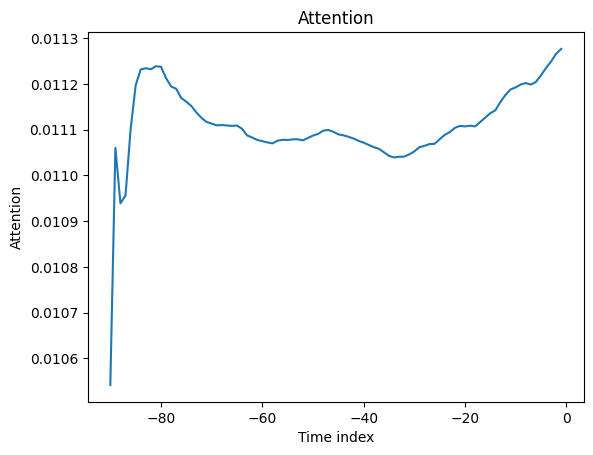

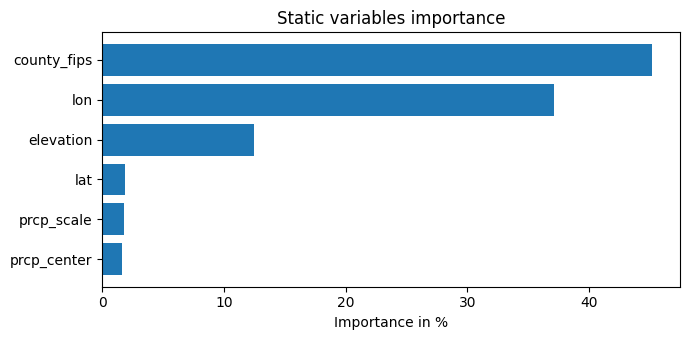

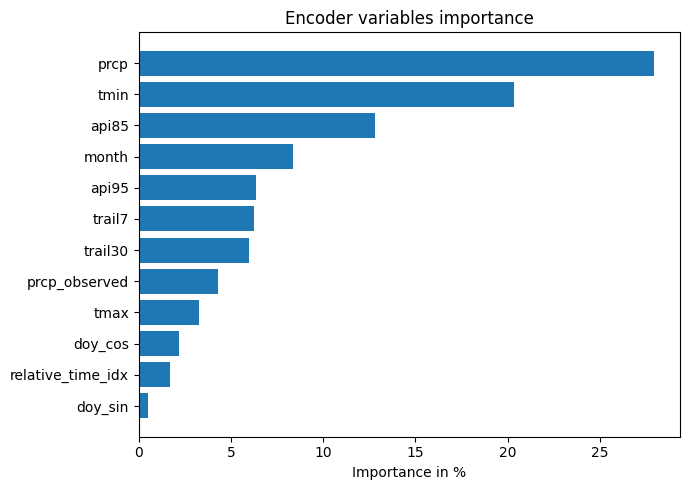

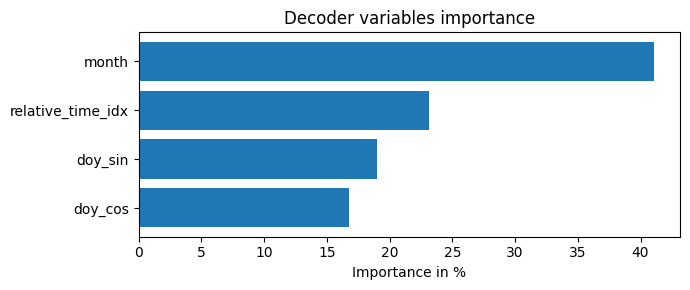

In [5]:
"""Temporal Fusion Transformer for Gulf Coast daily precipitation — Colab script.

Self-contained: reads the raw files from Drive, builds its own features, and
does not import anything from the local project.

The TFT predicts the daily precipitation *distribution* over the next 3 days via
quantile loss. Exceedance probability is then read off the predicted quantiles,
which is why this is the right job for a TFT rather than a classifier: XGBoost
gives one number per county-day, the TFT gives the whole predictive spread.

WHY THIS VERSION EXISTS
-----------------------
The previous script was run twice on the same three configs and disagreed with
itself: A scored 0.0150 then 0.0200, B scored 0.0234 then 0.0153. The spread
within one config was as large as the spread between configs, so the ablation
measured noise. Four changes fix that:

  1. Every run is seeded, and each config is trained at SEEDS = (0, 1, 2) so
     across-seed variance is measured instead of assumed away.
  2. The validation dataloader has a seeded generator, so the random subset
     `limit_val_batches` consumes is reproducible rather than fresh each run.
  3. The checkpoint is no longer selected on `val_loss`. Quantile loss on daily
     precipitation is dominated by the ~99% of ordinary days — it came out as
     2.0740 / 2.0799 / 2.0984 for three configs that differ by six input
     columns. Every epoch is now saved and the one with the best *validation
     exceedance AP* is chosen, which is the quantity the paper reports.
  4. The date-grouped bootstrap CI only ever measured test-set sampling
     variance. It is still reported, but now per seed, so a verdict that flips
     between seeds is visible instead of hidden.

A later audit found two more defects, fixed here:

  5. `validation` was built from the whole 2000-2019 frame with no
     `min_prediction_idx`, so all 646,440 training windows were validation
     windows too — 74.7% of `val_loss` was in-sample, and EarlyStopping was
     watching a loss that falls as the model memorises. Test and checkpoint
     selection were unaffected, so earlier test APs stand; the stopping rule
     did not.
  6. XGBoost was trained once on `random_state=0` and called deterministic.
     With subsample and colsample below 1 it is stochastic; a fixed seed
     freezes one draw. It is now seeded over the same three seeds and paired
     with the TFT, so the baseline's variance is measured rather than assumed.
"""

# %% =========================================================================
# SECTION 1 - install. Restart the runtime if Colab asks, then re-run 2 and 3.
# ===========================================================================
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("lightning") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "pytorch-forecasting>=1.3", "lightning>=2.2"],
        check=True,
    )

# %% =========================================================================
# SECTION 2 - config
# ===========================================================================
from pathlib import Path

# DRIVE_PATH is set once in the setup cell at the top of the notebook, so the
# path lives in exactly one place instead of being edited in all three cells.
# The fallback is for running this file directly as a .py.
try:
    DATA_DIR = Path(DRIVE_PATH)
except NameError:
    DATA_DIR = Path("/content/drive/MyDrive/ganesh climate data")

FILES = {
    "weather": "gulf_coast_historical.parquet",
    "svi": "svi_gulf_coast_counties (1).csv",
    "mapping": "station_county_mapping (1).csv",
    "stations": "gulf_coast_stations_official.csv",
}

START_YEAR = 2000          # widen to 1990 once the pipeline is proven
N_COUNTIES = 120           # None = all 356; start small, scale after it runs
MIN_COVERAGE = 0.95        # drop stations-counties with sparse precipitation

ENCODER_LEN = 90
# Every predicted day is scored, so none of the quantile-loss gradient is spent
# on horizons that get thrown away. The old PREDICT_LEN=7 wasted 4/7 of it.
PREDICT_LEN = 3

TRAIN_END = 2014
VAL_END = 2019
TEST_START_YEAR = 2019     # one warm-up year so 2020 windows have full encoders
EVAL_START_YEAR = 2020

# PILOT exists to prove the pipeline end to end on ~3 minutes of GPU per seed
# before committing five hours to it. Its average precisions are NOT results: two
# epochs is nowhere near convergence and EarlyStopping never gets to fire. It
# writes to its own CSV and its own checkpoint folder so pilot numbers can never
# be concatenated into the real table — merging two protocols into one table is
# the exact mistake that invalidated the previous pass.
PILOT = False

# An "epoch" is REAL_BATCHES*BATCH_SIZE windows, ~10% of the training index, so
# the ceiling is deliberately high and EarlyStopping decides where to stop.
REAL_EPOCHS = 2 if PILOT else 40
REAL_BATCHES = 500
# Raised from 100: val_loss on a 100-batch sample was noisy enough to move which
# epoch looked best. It now only gates when training stops, but a noisy stop
# signal still truncates the candidate list at a random point.
VAL_BATCHES = 200
# Raised from 5 because selection now happens after training. Stopping on
# val_loss too early would cut off epochs whose validation AP is still climbing.
PATIENCE = 8
BATCH_SIZE = 128
# 8, not 4. The bottleneck is Python assembling 90-day windows on the CPU, not
# the GPU — a 112K-param model running at 8 it/s is nowhere near an L4's limit.
# This speeds up both training and the per-epoch checkpoint scorings, which are
# together about half the runtime. Drop to 4 if a worker dies on RAM.
NUM_WORKERS = 8

# Three seeds per config. The whole point of this script: one number per config
# is not a result, it is a sample of size one.
SEEDS = (0, 1, 2)

# Checkpoint selection scores every saved epoch on held-out 2015-2019. Doing
# that on all 120 counties would cost more than the training run, so it uses
# every Nth county — a fixed subset is fine for *ranking* checkpoints against
# each other. Raise the stride if selection is slow, lower it if the chosen
# epoch looks unstable across seeds.
VAL_SCORE_STRIDE = 6

# --- ablation switches. Change one per run; the banner below labels the run. --
RUN_TAG = "C_no_svi_no_time"
USE_SVI_STATICS = False
USE_ABS_TIME = False

# Colab's local disk is wiped on disconnect, so the selected checkpoints and the
# results table live on Drive. Per-epoch candidates stay on local disk — writing
# ~14 of them per seed across the Drive mount is slow and they are disposable.
CKPT_DIR = DATA_DIR / ("checkpoints_pilot" if PILOT else "checkpoints")
LOCAL_CKPT = Path("/content/ckpt_tmp")
RESULTS_CSV = DATA_DIR / (
    "stage1_results_PILOT.csv" if PILOT else "stage1_results_seeded.csv"
)
RETRAIN = True

# try:
#     from google.colab import drive
#     drive.mount("/content/drive")
# except ImportError:
#     pass

# %% =========================================================================
# SECTION 3 - build the daily long frame
# ===========================================================================
import numpy as np
import pandas as pd


def fips(s):
    return s.astype("int64").astype(str).str.zfill(5)


def load_daily():
    mapping = pd.read_csv(DATA_DIR / FILES["mapping"])
    mapping["county_fips"] = fips(mapping["county_fips"])

    w = pd.read_parquet(
        DATA_DIR / FILES["weather"], columns=["STATION", "DATE", "PRCP", "TMAX", "TMIN"]
    )
    w = w[w["DATE"].dt.year >= START_YEAR]
    w = w.merge(mapping[["STATION", "county_fips"]], on="STATION", how="inner")

    daily = (
        w.groupby(["county_fips", "DATE"])
        .agg(prcp=("PRCP", "mean"), tmax=("TMAX", "mean"), tmin=("TMIN", "mean"))
        .reset_index()
    )

    # Complete the calendar so the TFT sees a regular daily series per county.
    grid = pd.MultiIndex.from_product(
        [
            sorted(daily["county_fips"].unique()),
            pd.date_range(daily["DATE"].min(), daily["DATE"].max(), freq="D"),
        ],
        names=["county_fips", "DATE"],
    )
    daily = daily.set_index(["county_fips", "DATE"]).reindex(grid).reset_index()

    cov = daily.groupby("county_fips")["prcp"].apply(lambda s: s.notna().mean())
    keep = cov[cov >= MIN_COVERAGE].index
    if N_COUNTIES:
        keep = cov.loc[keep].sort_values(ascending=False).head(N_COUNTIES).index
    daily = daily[daily["county_fips"].isin(keep)].copy()
    print(f"kept {daily.county_fips.nunique()} counties, {len(daily):,} county-days")
    return daily


def load_static():
    svi = pd.read_csv(DATA_DIR / FILES["svi"])
    svi["county_fips"] = fips(svi["FIPS"])
    svi = svi[
        ["county_fips", "RPL_THEME1", "RPL_THEME2", "RPL_THEME3", "RPL_THEME4",
         "RPL_THEMES", "E_TOTPOP", "AREA_SQMI"]
    ]
    svi["pop_density"] = svi["E_TOTPOP"] / svi["AREA_SQMI"].replace(0, np.nan)

    mapping = pd.read_csv(DATA_DIR / FILES["mapping"])
    mapping["county_fips"] = fips(mapping["county_fips"])
    geo = mapping.groupby("county_fips").agg(
        lat=("LATITUDE", "mean"), lon=("LONGITUDE", "mean")
    ).reset_index()

    st = pd.read_csv(DATA_DIR / FILES["stations"]).merge(
        mapping[["STATION", "county_fips"]], left_on="ID", right_on="STATION"
    )
    elev = st.groupby("county_fips")["ELEVATION"].mean().rename("elevation").reset_index()

    return geo.merge(elev, on="county_fips", how="left").merge(
        svi, on="county_fips", how="inner"
    )


def add_features(daily):
    daily = daily.sort_values(["county_fips", "DATE"]).reset_index(drop=True)

    # A zero and a missing observation mean different things; flag it rather
    # than letting the model treat an outage as a dry day.
    daily["prcp_observed"] = daily["prcp"].notna().astype("float32")
    daily["prcp"] = daily["prcp"].fillna(0.0)
    for c in ("tmax", "tmin"):
        daily[c] = daily.groupby("county_fips")[c].ffill().bfill()

    g = daily.groupby("county_fips", sort=False)["prcp"]
    # Antecedent Precipitation Index: the soil-moisture memory term.
    for k in (0.85, 0.95):
        daily[f"api{int(k * 100)}"] = g.transform(
            lambda s, k=k: s.ewm(alpha=1 - k, adjust=False).mean()
        )
    for w in (7, 30):
        daily[f"trail{w}"] = g.transform(
            lambda s, w=w: s.rolling(w, min_periods=2).sum()
        ).fillna(0.0)

    # Evaluation-only column: sum of prcp over [t, t+1, t+2], matching the three
    # decoder positions of a window whose first decoder index is t. NEVER goes
    # into the feature list — it contains the answer.
    daily["fwd3"] = g.transform(lambda s: s.rolling(3).sum().shift(-2))

    daily["time_idx"] = (
        daily["DATE"] - daily["DATE"].min()
    ).dt.days.astype("int64")
    daily["year"] = daily["DATE"].dt.year
    doy = daily["DATE"].dt.dayofyear
    daily["doy_sin"] = np.sin(2 * np.pi * doy / 365.25).astype("float32")
    daily["doy_cos"] = np.cos(2 * np.pi * doy / 365.25).astype("float32")
    daily["month"] = daily["DATE"].dt.month.astype(str)

    daily = daily.merge(load_static(), on="county_fips", how="inner")
    for c in daily.select_dtypes("float64").columns:
        daily[c] = daily[c].astype("float32")
    return daily


# Cached because Section 3 re-reads a 72 MB parquet over the Drive mount and
# redoes every groupby on each runtime restart. The key carries the only two
# settings that change the frame; delete the file if the feature code changes.
CACHE = DATA_DIR / f"daily_features_{N_COUNTIES or 'all'}_{START_YEAR}.parquet"
if CACHE.exists():
    daily = pd.read_parquet(CACHE)
    print(f"loaded cache {CACHE.name}")
else:
    daily = add_features(load_daily())
    daily.to_parquet(CACHE, index=False)
print(daily.shape)

# %% =========================================================================
# SECTION 4 - TimeSeriesDataSet
# ===========================================================================
import lightning.pytorch as pl
import torch
from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
from pytorch_forecasting import GroupNormalizer, TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_forecasting.metrics import QuantileLoss

torch.set_float32_matmul_precision("medium")

# SVI themes and population density are *vulnerability* variables with no
# mechanism for predicting rainfall; in a hazard model they can only act as a
# county fingerprint. Whether removing them actually helps is what the A/B
# comparison is for — the first attempt said +56% and the repeat said -35%.
STATIC_REALS = ["lat", "lon", "elevation"]
if USE_SVI_STATICS:
    STATIC_REALS += ["pop_density", "RPL_THEME1", "RPL_THEME2",
                     "RPL_THEME3", "RPL_THEME4", "RPL_THEMES"]

KNOWN_REALS = ["doy_sin", "doy_cos"] + (["time_idx"] if USE_ABS_TIME else [])

print(f"[{RUN_TAG}] counties={N_COUNTIES} from={START_YEAR} "
      f"svi={USE_SVI_STATICS} abs_time={USE_ABS_TIME} "
      f"statics={len(STATIC_REALS)} seeds={list(SEEDS)}")

train_cutoff = daily.loc[daily.year <= TRAIN_END, "time_idx"].max()
val_cutoff = daily.loc[daily.year <= VAL_END, "time_idx"].max()

# Frozen on the training years only. Defined here rather than in Section 7
# because checkpoint selection, test scoring and XGBoost all need it.
thr_by_county = (
    daily[daily.year <= TRAIN_END]
    .groupby("county_fips")["fwd3"].quantile(0.99).rename("thr")
)

# County x month climatology, also train-period only. Tier-0 comparator.
daily["_y3"] = (daily["fwd3"] >= daily["county_fips"].map(thr_by_county)).astype(float)
clim = (
    daily[daily.year <= TRAIN_END]
    .groupby(["county_fips", "month"])["_y3"].mean().rename("s_clim")
)


def make_dataset(df, max_idx, **kw):
    return TimeSeriesDataSet(
        df[df.time_idx <= max_idx],
        time_idx="time_idx",
        target="prcp",
        group_ids=["county_fips"],
        max_encoder_length=ENCODER_LEN,
        min_encoder_length=ENCODER_LEN,
        max_prediction_length=PREDICT_LEN,
        min_prediction_length=PREDICT_LEN,
        static_categoricals=["county_fips"],
        static_reals=STATIC_REALS,
        time_varying_known_categoricals=["month"],
        time_varying_known_reals=KNOWN_REALS,
        time_varying_unknown_reals=[
            "prcp", "tmax", "tmin", "api85", "api95", "trail7", "trail30",
            "prcp_observed",
        ],
        # Daily rainfall is zero-inflated and right-skewed; log1p inside a
        # per-county normalizer keeps the quantile head on a sane scale.
        target_normalizer=GroupNormalizer(
            groups=["county_fips"], transformation="log1p"
        ),
        add_relative_time_idx=True,
        add_target_scales=True,
        allow_missing_timesteps=True,
        **kw,
    )


training = make_dataset(daily, train_cutoff)

# min_prediction_idx is load-bearing. Without it this builds a window at every
# valid position in 2000-2019, so all 646,440 training windows are validation
# windows too and 74.7% of val_loss is in-sample — which makes EarlyStopping
# watch a loss that falls as the model memorises. Encoders still reach back into
# 2014, which is correct: reading the past is not leakage.
validation = TimeSeriesDataSet.from_dataset(
    training,
    daily[daily.time_idx <= val_cutoff],
    min_prediction_idx=train_cutoff + 1,
    predict=False,
    stop_randomization=True,
)
# Only the evaluation years, plus one warm-up year for the encoders. Scoring all
# 26 years and then discarding pre-2020 was ~4x wasted inference.
testing = TimeSeriesDataSet.from_dataset(
    training,
    daily[daily.year >= TEST_START_YEAR],
    predict=False,
    stop_randomization=True,
)

# Held-out slice used only to pick which epoch's weights to keep. 2014 is a
# warm-up year so that 2015 windows have full encoders; nothing from it is
# scored, and no test year is touched.
val_score_counties = sorted(daily.county_fips.unique())[::VAL_SCORE_STRIDE]
val_scoring = TimeSeriesDataSet.from_dataset(
    training,
    daily[(daily.year >= TRAIN_END) & (daily.year <= VAL_END)
          & daily.county_fips.isin(val_score_counties)],
    predict=False,
    stop_randomization=True,
)

print(f"train windows {len(training):,} | val {len(validation):,} | "
      f"test {len(testing):,} | select {len(val_scoring):,} "
      f"({len(val_score_counties)} counties)")

# Fails loudly if min_prediction_idx ever goes missing again. Validation must be
# strictly smaller than training here, because it covers 5 years against 15.
assert len(validation) < len(training), (
    f"validation ({len(validation):,}) >= training ({len(training):,}): the "
    "validation set is overlapping the training years again"
)
print(f"  validation decoder years: "
      f"{daily.loc[daily.time_idx == train_cutoff + 1, 'year'].iloc[0]}"
      f"-{VAL_END}, no training windows included")

test_dl = testing.to_dataloader(
    train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS
)
val_score_dl = val_scoring.to_dataloader(
    train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS
)

# %% =========================================================================
# SECTION 5 - scoring, shared by checkpoint selection and final evaluation
#
# Three scorings of the same predictions. The first is the naive one and it is
# expected to fail: average precision ranks globally, but the label is a
# *per-county* p99, so a wet county's high predicted quantiles carry no label
# information and only add between-county noise. The second and third remove
# that county scale, which is the comparison XGBoost has always had.
# ===========================================================================
from sklearn.metrics import average_precision_score


def to_np(t):
    return t.detach().cpu().numpy() if hasattr(t, "detach") else np.asarray(t)


def exceedance_scores(model, dl):
    """Return one row per window with the label and all four ranking scores."""
    out = model.predict(dl, mode="quantiles", return_index=True, return_y=True)

    qsum = to_np(out.output).sum(axis=1)     # (n, n_quantiles), 3-day totals
    # TFT quantile heads cross occasionally. The insertion-point search below
    # assumes a monotone vector, and on a crossed row it returns a count rather
    # than a position, which silently corrupts that row's s_prob.
    qsum = np.maximum.accumulate(qsum, axis=1)
    actual3 = to_np(out.y[0]).sum(axis=1)

    ev = out.index.reset_index(drop=True).assign(actual3=actual3)
    ev = ev.merge(daily[["county_fips", "time_idx", "year", "month"]],
                  on=["county_fips", "time_idx"], how="left")
    ev = ev.join(thr_by_county, on="county_fips").dropna(subset=["thr"])
    ev["y"] = (ev["actual3"] >= ev["thr"]).astype(int)

    qsum = qsum[ev.index.to_numpy()]
    thr = ev["thr"].to_numpy()

    # scoring 1: raw upper quantile, county scale left in
    ev["s_raw"] = qsum[:, -1]
    # scoring 2: upper quantile divided by the county's own threshold
    ev["s_ratio"] = qsum[:, -1] / thr
    # scoring 3: P(3-day total > county threshold), interpolated across the
    # predicted quantile vector. The quantile of a sum is not the sum of
    # quantiles, so this is a ranking score, not a calibrated probability.
    L = np.asarray(model.loss.quantiles, dtype=float)
    k = (qsum < thr[:, None]).sum(axis=1)
    k_lo, k_hi = np.clip(k - 1, 0, len(L) - 1), np.clip(k, 0, len(L) - 1)
    v_lo = np.take_along_axis(qsum, k_lo[:, None], 1).ravel()
    v_hi = np.take_along_axis(qsum, k_hi[:, None], 1).ravel()
    span = np.where(v_hi > v_lo, v_hi - v_lo, 1.0)
    frac = np.clip((thr - v_lo) / span, 0.0, 1.0)
    cdf = L[k_lo] + frac * (L[k_hi] - L[k_lo])
    cdf = np.where(k == 0, 0.0, np.where(k == len(L), 1.0, cdf))
    ev["s_prob"] = 1.0 - cdf

    ev = ev.join(clim, on=["county_fips", "month"])
    ev["s_clim"] = ev["s_clim"].fillna(ev["s_clim"].mean())
    return ev.reset_index(drop=True)


SCORINGS = [
    ("county x month climatology", "s_clim"),
    ("TFT  raw upper quantile", "s_raw"),
    ("TFT  quantile / county threshold", "s_ratio"),
    ("TFT  exceedance probability", "s_prob"),
]

# %% =========================================================================
# SECTION 6 - SMOKE TEST: can the model overfit a tiny subset?
# If the loss does not collapse here, something is wrong with the windowing or
# the target. Catching it on 100 samples costs 30 seconds; catching it after a
# full run costs an evening.
# ===========================================================================
pl.seed_everything(SEEDS[0], workers=True)

tiny_counties = daily.county_fips.unique()[:2]
tiny = daily[
    (daily.county_fips.isin(tiny_counties)) & (daily.time_idx <= daily.time_idx.min() + 400)
]
tiny_ds = make_dataset(tiny, tiny.time_idx.max())
tiny_dl = tiny_ds.to_dataloader(train=True, batch_size=32, num_workers=0)

tiny_model = TemporalFusionTransformer.from_dataset(
    tiny_ds,
    learning_rate=0.05,
    hidden_size=16,
    attention_head_size=2,
    dropout=0.0,
    hidden_continuous_size=8,
    loss=QuantileLoss(),
    optimizer="adam",
)
pl.Trainer(
    max_epochs=40, accelerator="auto", devices=1, enable_progress_bar=True,
    logger=False, enable_checkpointing=False, gradient_clip_val=0.1,
).fit(tiny_model, train_dataloaders=tiny_dl)
print("\nSmoke test done. The training loss above must fall substantially.")
print("If it is flat, STOP and debug before running Section 7.")

# %% =========================================================================
# SECTION 7 - train one model per seed, select its epoch on validation AP
#
# `val_loss` is deliberately NOT the selection criterion. It is quantile loss
# over daily precipitation, so the ~99% of ordinary days drown out the extremes
# the paper is about: three configs differing by six input columns scored
# 2.0740 / 2.0799 / 2.0984. It is kept only to decide when to stop training.
# ===========================================================================
import shutil
import time

per_seed = {}
LOCAL_CKPT.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

for SEED in SEEDS:
    t0 = time.time()
    final_ckpt = CKPT_DIR / f"{RUN_TAG}-seed{SEED}.ckpt"

    if not RETRAIN and final_ckpt.exists():
        best = TemporalFusionTransformer.load_from_checkpoint(str(final_ckpt))
        print(f"\n[seed {SEED}] loaded {final_ckpt.name} — skipped training")
    else:
        pl.seed_everything(SEED, workers=True)

        tmp = LOCAL_CKPT / f"{RUN_TAG}_seed{SEED}"
        if tmp.exists():
            shutil.rmtree(tmp)
        tmp.mkdir(parents=True)

        # Explicit generator, not the global RNG. Without it the batch order
        # depends on how many draws model construction happened to consume,
        # which differs between A/B/C because they have different parameter
        # counts — so "seed 0" would not mean the same shuffle across configs.
        train_dl = training.to_dataloader(
            train=True, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
            persistent_workers=True,
            generator=torch.Generator().manual_seed(SEED),
        )
        # shuffle=True matters because limit_val_batches takes the *first* n
        # batches and the dataset index is ordered by county. The seeded
        # generator is what makes the subset reproducible between runs — without
        # it, every run validated on a different sample and the epoch that
        # looked best was partly a coin flip.
        val_dl = validation.to_dataloader(
            train=False, batch_size=BATCH_SIZE * 4, num_workers=NUM_WORKERS,
            persistent_workers=True, shuffle=True,
            generator=torch.Generator().manual_seed(SEED),
        )

        model = TemporalFusionTransformer.from_dataset(
            training,
            learning_rate=0.01,
            hidden_size=32,
            attention_head_size=4,
            dropout=0.15,
            hidden_continuous_size=16,
            loss=QuantileLoss(),
            optimizer="adam",
            log_interval=50,
            reduce_on_plateau_patience=2,
        )
        if SEED == SEEDS[0]:
            print(f"{model.size() / 1e3:.1f}k parameters")

        # save_top_k=-1: keep every epoch, because the epoch that minimises
        # val_loss is not the epoch that maximises validation AP.
        ckpt = ModelCheckpoint(
            dirpath=str(tmp), filename="{epoch:02d}",
            save_top_k=-1, every_n_epochs=1,
        )
        trainer = pl.Trainer(
            max_epochs=REAL_EPOCHS,
            limit_train_batches=REAL_BATCHES,
            limit_val_batches=VAL_BATCHES,
            accelerator="auto",
            devices=1,
            gradient_clip_val=0.1,
            deterministic="warn",
            callbacks=[
                EarlyStopping(monitor="val_loss", patience=PATIENCE, mode="min"),
                LearningRateMonitor(),
                ckpt,
            ],
        )
        trainer.fit(model, train_dataloaders=train_dl, val_dataloaders=val_dl)
        del train_dl, val_dl

        cands = sorted(tmp.glob("*.ckpt"))
        print(f"\n[seed {SEED}] trained {trainer.current_epoch} epochs, "
              f"scoring {len(cands)} checkpoints on held-out {TRAIN_END + 1}-{VAL_END}")

        sel_ap, sel_path = -1.0, None
        for p in cands:
            m = TemporalFusionTransformer.load_from_checkpoint(str(p))
            vs = exceedance_scores(m, val_score_dl)
            vs = vs[vs.year > TRAIN_END]
            ap = average_precision_score(vs["y"], vs["s_prob"])
            flag = ""
            if ap > sel_ap:
                sel_ap, sel_path, flag = ap, p, "  <-- best so far"
            print(f"    {p.stem}  val AP {ap:.4f}{flag}")
            del m
            torch.cuda.empty_cache()

        shutil.copy(sel_path, final_ckpt)
        shutil.rmtree(tmp)
        best = TemporalFusionTransformer.load_from_checkpoint(str(final_ckpt))
        print(f"[seed {SEED}] selected {sel_path.stem} "
              f"(val AP {sel_ap:.4f}) -> {final_ckpt.name}")

    ev = exceedance_scores(best, test_dl)
    per_seed[SEED] = ev[ev.year >= EVAL_START_YEAR].reset_index(drop=True)
    print(f"[seed {SEED}] done in {(time.time() - t0) / 60:.1f} min")

# --- per-seed and across-seed test results ----------------------------------
prev = per_seed[SEEDS[0]]["y"].mean()
print(f"\nnext-3-day extreme rainfall, test {EVAL_START_YEAR}-2026")
print(f"  n {len(per_seed[SEEDS[0]]):,}  "
      f"positives {per_seed[SEEDS[0]].y.sum():,}  prevalence {prev:.4f}\n")

ap_table = pd.DataFrame(
    {col: {s: average_precision_score(te["y"], te[col])
           for s, te in per_seed.items()}
     for _, col in SCORINGS}
)
ap_table.index.name = "seed"

print(f"  {'scoring':<34} " + "".join(f"seed {s:<6}" for s in SEEDS)
      + f"{'mean':<9}{'std':<9}lift")
for name, col in SCORINGS:
    v = ap_table[col].to_numpy()
    print(f"  {name:<34} " + "".join(f"{x:<11.4f}" for x in v)
          + f"{v.mean():<9.4f}{v.std(ddof=1):<9.4f}{v.mean() / prev:.2f}x")

spread = ap_table["s_prob"].max() - ap_table["s_prob"].min()
print(f"\n  across-seed spread of the headline score (s_prob): {spread:.4f}")
print("  Any ablation effect smaller than this is not measurable with 3 seeds.")

# %% =========================================================================
# SECTION 8 - interpretability, on the median seed
# ===========================================================================
median_seed = ap_table["s_prob"].sort_values().index[len(SEEDS) // 2]
print(f"interpreting seed {median_seed} (median test AP)")
best = TemporalFusionTransformer.load_from_checkpoint(
    str(CKPT_DIR / f"{RUN_TAG}-seed{median_seed}.ckpt")
)
# mode="raw" keeps the attention tensor for every window, so running it over all
# 324,480 test windows is an out-of-memory crash, not a slow cell. Attention is
# averaged with reduction="sum" anyway, so a few thousand windows give the same
# picture; the interp dataloader is deliberately a thin slice.
interp = TimeSeriesDataSet.from_dataset(
    training,
    daily[(daily.year == EVAL_START_YEAR)
          & daily.county_fips.isin(val_score_counties[:4])],
    predict=False,
    stop_randomization=True,
)
print(f"  interpreting over {len(interp):,} windows (4 counties, "
      f"{EVAL_START_YEAR} only)")
raw = best.predict(
    interp.to_dataloader(train=False, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS),
    mode="raw", return_x=True,
)
best.plot_interpretation(best.interpret_output(raw.output, reduction="sum"))

# %% =========================================================================
# SECTION 9 - head-to-head: XGBoost on IDENTICAL rows and IDENTICAL features
#
# XGBoost is seeded over the SAME three seeds as the TFT. The earlier script
# trained it once and argued `random_state=0` made it deterministic — but with
# subsample=0.8 and colsample_bytree=0.7 the method is stochastic, and fixing
# the seed freezes one draw rather than removing the variance. Measuring the
# TFT's training variance and then comparing it against a single unmeasured
# baseline draw is the same error that invalidated the first ablation.
#
# Seeds are paired: TFT seed s against XGBoost seed s. The bootstrap CI is also
# per pair, which is the point — in the earlier script one seed printed
# SIGNIFICANT with a tight interval while a repeat of the same config disagreed
# by more than that interval's width.
# ===========================================================================
import xgboost as xgb

FEAT = ["prcp", "tmax", "tmin", "prcp_observed", "api85", "api95",
        "trail7", "trail30", "doy_sin", "doy_cos", "lat", "lon", "elevation"]

# Features are read at t-1, matching the TFT encoder, which ends the day before
# the first decoder step. Shifting time_idx forward relabels row t-1 as t.
origin = daily[["county_fips", "time_idx"] + FEAT].copy()
origin["time_idx"] += 1

lab = daily[["county_fips", "time_idx", "year", "fwd3"]].copy()
lab = lab.join(thr_by_county, on="county_fips").dropna(subset=["thr", "fwd3"])
lab["y"] = (lab["fwd3"] >= lab["thr"]).astype(int)

xd = lab.merge(origin, on=["county_fips", "time_idx"], how="inner").dropna(subset=FEAT)
tr = xd[xd.year <= TRAIN_END]
va = xd[(xd.year > TRAIN_END) & (xd.year <= VAL_END)]
xte = xd.merge(per_seed[SEEDS[0]][["county_fips", "time_idx"]].drop_duplicates(),
               on=["county_fips", "time_idx"], how="inner")

spw = (len(tr) - tr.y.sum()) / max(tr.y.sum(), 1)

xgb_pred, xgb_ap = {}, {}
for XSEED in SEEDS:
    clf = xgb.XGBClassifier(
        n_estimators=1500, learning_rate=0.05, max_depth=6, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.7, reg_lambda=2.0, scale_pos_weight=spw,
        eval_metric="aucpr", early_stopping_rounds=60, tree_method="hist",
        n_jobs=-1, random_state=XSEED,
    )
    clf.fit(tr[FEAT], tr.y, eval_set=[(va[FEAT], va.y)], verbose=False)
    xgb_pred[XSEED] = xte[["county_fips", "time_idx", "y"]].assign(
        p_xgb=clf.predict_proba(xte[FEAT])[:, 1]
    )
    xgb_ap[XSEED] = average_precision_score(xte["y"], xgb_pred[XSEED]["p_xgb"])
    print(f"  xgb seed {XSEED}: {clf.best_iteration + 1} trees, "
          f"test AP {xgb_ap[XSEED]:.4f}")

xv = np.array([xgb_ap[s] for s in SEEDS])
print(f"  XGBoost across-seed: mean {xv.mean():.4f}  std {xv.std(ddof=1):.4f}  "
      f"spread {xv.max() - xv.min():.4f}")

print("\nhead-to-head, identical rows / features / thresholds, seeds paired")
h2h = {}
for SEED, te in per_seed.items():
    cmp = xgb_pred[SEED].merge(te[["county_fips", "time_idx", "s_prob"]],
                               on=["county_fips", "time_idx"], how="inner").reset_index(drop=True)
    prev_c = cmp["y"].mean()

    # Resample whole days, not rows: one storm covers many counties on one date,
    # so row-level resampling would badly understate the interval. Note this
    # captures test-set sampling variance only — the across-seed spread above is
    # the other half of the uncertainty and the two must be read together.
    rng = np.random.default_rng(0)
    by_day = cmp.groupby("time_idx").indices
    days = np.array(list(by_day))
    a_x, a_t, diff = [], [], []
    for _ in range(200):
        sel = np.concatenate([by_day[d] for d in rng.choice(days, len(days), replace=True)])
        s = cmp.iloc[sel]
        if s["y"].sum() == 0:
            continue
        ax = average_precision_score(s["y"], s["p_xgb"])
        at = average_precision_score(s["y"], s["s_prob"])
        a_x.append(ax)
        a_t.append(at)
        diff.append(ax - at)

    lo, hi = np.percentile(diff, [2.5, 97.5])
    verdict = "SIGNIFICANT" if lo > 0 or hi < 0 else "NOT significant"
    h2h[SEED] = dict(n=len(cmp), prevalence=prev_c, ap_xgb=float(np.mean(a_x)),
                     ap_tft=float(np.mean(a_t)), diff=float(np.mean(diff)),
                     ci_lo=lo, ci_hi=hi, significant=verdict)
    print(f"  seed {SEED}:  n {len(cmp):,}  prevalence {prev_c:.4f}  "
          f"XGB {np.mean(a_x):.4f} ({np.mean(a_x) / prev_c:.2f}x)  "
          f"TFT {np.mean(a_t):.4f} ({np.mean(a_t) / prev_c:.2f}x)  "
          f"diff {np.mean(diff):+.4f} [{lo:+.4f}, {hi:+.4f}]  {verdict}")

verdicts = {v["significant"] for v in h2h.values()}
print(f"\n  verdict across seeds: "
      + ("STABLE — " + verdicts.pop() if len(verdicts) == 1
         else "UNSTABLE, the comparison flips between seeds: " + ", ".join(sorted(verdicts))))

# The gap only means something if it is larger than the variance of BOTH models.
gap = float(np.mean([v["diff"] for v in h2h.values()]))
noise = max(spread, xv.max() - xv.min())
print(f"  mean XGB - TFT gap {gap:+.4f} vs largest training spread {noise:.4f}: "
      + ("gap exceeds training noise" if abs(gap) > noise
         else "gap is WITHIN training noise, not a finding"))

if PILOT:
    print("\n" + "=" * 70)
    print("PILOT RUN — 2 epochs per seed. Every AP above is pre-convergence and")
    print("must not be quoted, compared across configs, or put in the paper.")
    print("What it does prove: the data, windowing, seeding, selection, scoring")
    print("and XGBoost paths all execute. Set PILOT = False for real numbers.")
    print("=" * 70)

# %% =========================================================================
# SECTION 10 - append one row per seed to the results table on Drive
# ===========================================================================
rows = pd.DataFrame([{
    "run_tag": RUN_TAG,
    "seed": SEED,
    "pilot": PILOT,
    "epochs_cap": REAL_EPOCHS,
    "counties": daily.county_fips.nunique(),
    "start_year": START_YEAR,
    "svi_statics": USE_SVI_STATICS,
    "abs_time": USE_ABS_TIME,
    "n_rows": h2h[SEED]["n"],
    "prevalence": h2h[SEED]["prevalence"],
    "ap_climatology": ap_table.loc[SEED, "s_clim"],
    "ap_tft_raw": ap_table.loc[SEED, "s_raw"],
    "ap_tft_ratio": ap_table.loc[SEED, "s_ratio"],
    "ap_tft_prob": ap_table.loc[SEED, "s_prob"],
    "ap_xgb": h2h[SEED]["ap_xgb"],
    "xgb_minus_tft": h2h[SEED]["diff"],
    "ci_lo": h2h[SEED]["ci_lo"],
    "ci_hi": h2h[SEED]["ci_hi"],
    "significant": h2h[SEED]["significant"],
} for SEED in SEEDS])

if RESULTS_CSV.exists():
    rows = pd.concat([pd.read_csv(RESULTS_CSV), rows], ignore_index=True)
    rows = rows.drop_duplicates(subset=["run_tag", "seed"], keep="last")
rows = rows.sort_values(["run_tag", "seed"])
rows.to_csv(RESULTS_CSV, index=False)
print(f"\nsaved to {RESULTS_CSV.name}")
print(rows.to_string(index=False))

print("\nper-config summary across seeds")
print(rows.groupby("run_tag")["ap_tft_prob"].agg(["mean", "std", "min", "max"]).to_string())
